# Proyecto final · Procesamiento de Lenguaje Natural
## Clasificador de reseñas por sede para priorizar quejas · caso Bodytech

**Maestría en Ciencia de Datos · Universidad Ean** · Docente: Gerson José Moreno Morales
**Equipo:** Jesús Joseph Suescun (Gerencia de IA) · Fabián David Sánchez (Machine Learning) · David Vallejo Villegas (Ciencia de Datos)

| | |
|---|---|
| **Problema** | Las reseñas negativas de una sede llegan tarde, o no llegan, al coordinador. Si nadie contacta al afiliado insatisfecho, aumenta el riesgo de que cancele su plan. |
| **Usuario** | El coordinador de cada sede y el equipo de servicio al cliente. |
| **Decisión que apoya** | Para cada reseña: **alerta al coordinador** (posible queja), **revisión humana** (el modelo no está seguro) o **registro automático**. |
| **Datos** | No existe un corpus público de reseñas de gimnasios en español. Se usan 18.172 reseñas reales de hoteles de Andalucía (Big_AHR, TripAdvisor) como *proxy*: el hotel hace de sede y la provincia de ciudad. **El caso Bodytech es simulado.** |
| **Modelos** | Baseline TF-IDF + regresión logística · BiLSTM (embedding aleatorio y Word2Vec) · BETO (notebook 02, Colab con GPU) |

**Mapa del notebook:** 1 configuración · 2 prerregistro · 3 exploración (EDA) · 4 limpieza · 5 partición por sede · 6 anonimización y corpus · 7 baseline · 8 BiLSTM · 9 evaluación en test · 10 política de decisión · 11 segmentos · 12 errores · 13 robustez · 14 monitoreo y *drift* · 15 BETO · 16 criterio de adopción y conclusiones.

**Cómo ejecutarlo:** *Entorno de ejecución → Ejecutar todo*. En Colab, la primera celda clona el repositorio e instala lo que falta; en un equipo local, instale antes `requirements.txt` (ver README). La ejecución completa tardó 16 minutos en un equipo de 2 núcleos sin GPU.

In [1]:
# Solo en Google Colab: clonar el repositorio (trae datos, código y artefactos) e instalar lo que Colab no trae.
# En un equipo local no hace nada: allí se instala requirements.txt (ver README).
import sys, os, subprocess, importlib.util
if 'google.colab' in sys.modules and not os.path.exists('src/texto.py'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/DavidVallejoV/proyecto-final-pln'], check=True)
    os.chdir('proyecto-final-pln')
    faltan = ['langdetect', 'gensim>=4.4', 'python-dotenv'] + [p for p in ['tensorflow', 'spacy'] if importlib.util.find_spec(p) is None]
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltan], check=True)
    subprocess.run([sys.executable, '-m', 'spacy', 'download', 'es_core_news_sm'], check=True, capture_output=True)
    print('Repositorio listo en', os.getcwd())

## 1. Configuración y reproducibilidad
Semilla única (42) para Python, NumPy y TensorFlow; rutas relativas a la raíz del repositorio (sirve igual desde `notebooks/` o desde la raíz); todo el preprocesamiento se importa de `src/`, el mismo código que usa la demo.

In [2]:
# 1. Configuración, reproducibilidad y registro del entorno
import os, sys, re, gc, json, time, random, platform, warnings, collections, subprocess, unicodedata
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'texto.py').exists())   # sirve desde notebooks/ o desde la raíz
sys.path.insert(0, str(RAIZ))
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib, gensim, spacy
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, f1_score, recall_score, precision_score, log_loss, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

from src import config
from src.texto import (normalizar, a_secuencia, sin_tildes, detectar_idioma, enmascarar_sede, palabras_de_nombre,
                       Anonimizador, construir_lexico)
from src.particion import partir_por_grupo
from src.modelos import crear_baseline, evidencia, palabras_desconocidas

SEED = config.SEMILLA
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
warnings.filterwarnings('ignore'); tf.get_logger().setLevel('ERROR')
pd.set_option('display.max_colwidth', 150); pd.set_option('display.width', 220)
T_INICIO = time.time()
for d in [config.DIR_RESULTADOS, config.DIR_FIGURAS, config.DIR_MODELOS, config.RUTA_CORPUS.parent, config.RUTA_POLITICA.parent]:
    d.mkdir(parents=True, exist_ok=True)

def guardar_figura(nombre):
    """Guarda la figura actual en resultados/figuras/ (la usan el informe y la presentación)."""
    plt.savefig(config.DIR_FIGURAS / f'{nombre}.png', dpi=150, bbox_inches='tight')

def ram_gb():
    try:
        return round(os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9, 1)
    except (ValueError, OSError, AttributeError):
        return None

ENTORNO = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
           'tensorflow': tf.__version__, 'gensim': gensim.__version__, 'spacy': spacy.__version__, 'sistema': platform.platform(),
           'procesador': platform.processor() or platform.machine(), 'núcleos': os.cpu_count(), 'RAM (GB)': ram_gb(),
           'GPU': bool(tf.config.list_physical_devices('GPU')), 'semilla': SEED}
(config.DIR_RESULTADOS / 'entorno.json').write_text(json.dumps(ENTORNO, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.Series(ENTORNO, name='valor').to_frame())

,valor
python,3.13.18
numpy,2.5.3
pandas,3.0.5
scikit-learn,1.9.1
tensorflow,2.21.0
gensim,4.4.0
spacy,3.8.18
sistema,Linux-6.18.44-fc-v726-x86_64-with-glibc2.39
procesador,x86_64
núcleos,2


Las versiones, el hardware (2 núcleos, 8,4 GB de RAM, sin GPU) y la semilla quedan en `resultados/entorno.json`. Con eso cualquier persona puede saber en qué condiciones se obtuvieron las cifras.

## 2. Prerregistro: las reglas del juego antes de ver resultados
Antes de entrenar se fija cómo se va a juzgar el proyecto, para no acomodar el criterio a lo que salga.
- **Métrica principal: F1 macro en test, con sedes que el modelo nunca vio.** Es el promedio simple del F1 de las tres clases. Se usa porque la positiva es el 73 % de los datos: un modelo que siempre dijera «positiva» acertaría el 73 % sin servir para nada.
- **Clase crítica: negativa.** Una queja que no llega al coordinador cuesta más que una alerta de más.
- **Criterio de adopción del modelo avanzado:** al menos +0,02 de F1 macro sobre el baseline, recall de negativas ≥ 0,90 con la regla de alerta, latencia p95 < 100 ms por reseña en CPU y menos del 25 % de reseñas a revisión por baja confianza.

In [3]:
# 2. Prerregistro: métrica, clase crítica, criterios de adopción e hipótesis, fijados ANTES de ver resultados
CLASES = config.CLASES                  # ['negativa', 'neutra', 'positiva']
CLASE_CRITICA = config.CLASE_CRITICA    # 'negativa': un usuario insatisfecho que nadie atiende puede cancelar su plan
METRICA_PRINCIPAL = 'F1 macro en test con sedes no vistas'
CRITERIOS = {'mejora_f1_macro': 0.02,   # el modelo avanzado debe superar al baseline por al menos 0,02 de F1 macro
             'recall_critico': 0.90,    # recall mínimo de la clase crítica (con la regla de alerta)
             'latencia_p95_ms': 100,    # tiempo máximo por reseña en CPU
             'abstencion_max': 0.25}    # máximo de reseñas enviadas a revisión humana por baja confianza
CALIDAD_AUTO = 0.90                     # acierto mínimo en lo que el modelo decide solo (fija el umbral de abstención)
PRESUPUESTO = dict(embed_dim=64, units=64, dropout=0.3, lr=1e-3, epochs=15, batch_size=64, paciencia=3)
SEMILLAS = [42, 1, 2, 3, 4]             # cada red se entrena 5 veces para medir cuánto cambia el resultado por azar
HIPOTESIS = {
    'H1': 'Un modelo avanzado (BiLSTM o BETO) supera al baseline TF-IDF en al menos 0,02 de F1 macro sin perder más de 0,01 de recall de negativas.',
    'H2': 'Iniciar la BiLSTM con vectores de Word2Vec la mejora frente a vectores al azar (el cuello de botella es el embedding).',
    'H3': 'La clase neutra es la más difícil para todos los modelos.'}
prerregistro = dict(metrica_principal=METRICA_PRINCIPAL, clase_critica=CLASE_CRITICA, criterios=CRITERIOS, calidad_auto=CALIDAD_AUTO,
                    presupuesto_redes=PRESUPUESTO, semillas=SEMILLAS, hipotesis=HIPOTESIS)
(config.DIR_RESULTADOS / 'prerregistro.json').write_text(json.dumps(prerregistro, indent=2, ensure_ascii=False), encoding='utf-8')
for k, v in HIPOTESIS.items(): print(k, '·', v)

H1 · Un modelo avanzado (BiLSTM o BETO) supera al baseline TF-IDF en al menos 0,02 de F1 macro sin perder más de 0,01 de recall de negativas.
H2 · Iniciar la BiLSTM con vectores de Word2Vec la mejora frente a vectores al azar (el cuello de botella es el embedding).
H3 · La clase neutra es la más difícil para todos los modelos.


Quedan escritas las tres hipótesis que se contrastan en la sección 16 y el presupuesto de las redes: los mismos hiperparámetros para todas las variantes y 5 semillas por variante. Todo se guarda en `resultados/prerregistro.json`.

## 3. Exploración de datos (EDA)
Preguntas que guían la exploración: ¿qué tan desbalanceadas están las clases?, ¿hay duplicados que inflen las métricas?, ¿todas las filas vienen de la misma fuente?, ¿qué tan largas son las reseñas?, ¿hay otros idiomas o datos personales?, ¿cuántas reseñas tiene cada sede?

In [4]:
# 3.1 Carga y diccionario del archivo original
df = pd.read_csv(config.RUTA_DATOS_CRUDOS).rename(columns={'Unnamed: 0': 'id'})
DESCRIPCION = {'id': 'Índice de la fila en el archivo original (identificador estable)',
               'title': 'Título de la reseña escrito por el huésped',
               'rating': 'Calificación de 1 a 5 estrellas',
               'review_text': 'Texto de la reseña',
               'location': 'Ubicación del hotel: municipio, provincia y comunidad (en Bodytech: la ciudad)',
               'hotel': 'Nombre del hotel (en Bodytech: la sede)',
               'label': 'Etiqueta de sentimiento derivada de rating (0 negativa, 3 neutra, 1 positiva)'}
diccionario_crudo = pd.DataFrame({'tipo': df.dtypes.astype(str), 'nulos': df.isna().sum(), 'valores distintos': df.nunique(),
                                  'ejemplo': df.iloc[0].astype(str).str.slice(0, 50), 'descripción': pd.Series(DESCRIPCION)})
print(f'{len(df)} filas · {df.shape[1]} columnas')
display(diccionario_crudo)

18172 filas · 7 columnas


,tipo,nulos,valores distintos,ejemplo,descripción
id,int64,0,18172,0,Índice de la fila en el archivo original (identificador estable)
title,str,0,10262,Excelente y personal amable,Título de la reseña escrito por el huésped
rating,int64,0,5,5,Calificación de 1 a 5 estrellas
review_text,str,0,13330,Un hotel muy bueno. El personal fue muy amable y,Texto de la reseña
location,str,1816,33,Seville_Province_of_Seville_Andalucia,"Ubicación del hotel: municipio, provincia y comunidad (en Bodytech: la ciudad)"
hotel,str,1816,715,H10_Casa_de_la_Plata,Nombre del hotel (en Bodytech: la sede)
label,int64,0,3,1,"Etiqueta de sentimiento derivada de rating (0 negativa, 3 neutra, 1 positiva)"


18.172 filas y 7 columnas. `hotel` y `location` están vacías en las mismas 1.816 filas: es la primera pista de que el archivo mezcla dos fuentes (ver más abajo).

In [5]:
# 3.2 ¿De dónde sale la etiqueta? Se cruza con la calificación en estrellas
display(pd.crosstab(df.rating, df.label))
ETIQUETA = {0: 'negativa', 3: 'neutra', 1: 'positiva'}
df['sentimiento'] = df.label.map(ETIQUETA)
display(pd.DataFrame({'n': df.sentimiento.value_counts(), '%': df.sentimiento.value_counts(normalize=True).mul(100).round(1)}))

label,0,1,3
rating,,,
1,1677,0,0
2,994,0,0
3,0,0,2274
4,0,4222,0
5,0,9005,0


,n,%
sentimiento,,
positiva,13227,72.8
negativa,2671,14.7
neutra,2274,12.5


La etiqueta sale de las estrellas (1-2★ negativa, 3★ neutra, 4-5★ positiva); la columna `label` usa códigos poco intuitivos (0, 3, 1) y se reemplaza por `sentimiento`. **Desbalance fuerte:** 72,8 % positivas, 14,7 % negativas y 12,5 % neutras.
**Decisiones:** F1 macro como métrica y clases balanceadas en el entrenamiento.
**Ojo:** la etiqueta es la calificación del autor, no una lectura del texto. Una reseña de 3★ puede tener un texto muy positivo o muy negativo; eso explica buena parte de los errores (sección 12).

In [6]:
# 3.3 Duplicados exactos y casi-duplicados
COLS = ['title', 'review_text', 'rating', 'label']
print('Filas del archivo:', len(df))
print(f'Duplicados exactos: {df.duplicated(subset=COLS).sum()} ({df.duplicated(subset=COLS).mean():.1%} del archivo)')
print('¿Algún texto repetido aparece con etiquetas distintas?', (df.groupby('review_text').label.nunique() > 1).any())
veces = df.groupby(COLS).size()
display(veces.value_counts().sort_index().rename('reseñas').rename_axis('veces que aparece').to_frame().T)
def plantilla(s):
    s = unicodedata.normalize('NFKD', str(s).lower()); s = ''.join(c for c in s if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z ]', ' ', s)).strip()
u = df.drop_duplicates(subset=COLS).copy().reset_index(drop=True)
clave = u.review_text.map(plantilla)
print(f'Reseñas únicas: {len(u)} | claves de plantilla distintas: {clave.nunique()} | claves con etiquetas en conflicto: '
      f'{(u.groupby(clave.values).label.nunique() > 1).sum()}')

Filas del archivo: 18172


Duplicados exactos: 4841 (26.6% del archivo)
¿Algún texto repetido aparece con etiquetas distintas? False


veces que aparece,1,2,3,4,5,6,8,12,16
reseñas,10109,2407,201,553,20,23,9,5,4


Reseñas únicas: 13331 | claves de plantilla distintas: 13330 | claves con etiquetas en conflicto: 0


**4.841 filas (26,6 %) son copias exactas**; algunas reseñas aparecen hasta 16 veces. Ninguna copia tiene etiquetas distintas.
**Decisión:** quitar los duplicados antes de partir. Si una copia queda en train y otra en test, el modelo «recuerda» en lugar de generalizar (al final de la sección 6 se mide cuánto infla eso el resultado). Quedan **13.331 reseñas únicas**.

In [7]:
# 3.4 Dos fuentes en el mismo archivo: reseñas con hotel (A) y sin hotel (B)
df['fuente'] = np.where(df.hotel.isna(), 'B (sin sede)', 'A (con sede)')
u['fuente'] = np.where(u.hotel.isna(), 'B (sin sede)', 'A (con sede)')
u['n_palabras'] = u.review_text.str.split().str.len(); u['n_chars'] = u.review_text.str.len()
anios = u.review_text.str.extractall(r'\b(20[0-2]\d)\b')[0].astype(int).rename('anio').reset_index()
anios['fuente'] = anios['level_0'].map(u.fuente)
perfil = pd.DataFrame({
    'filas en el archivo': df.fuente.value_counts(), 'reseñas únicas': u.fuente.value_counts(),
    '% negativa': u.groupby('fuente').sentimiento.apply(lambda s: (s == 'negativa').mean() * 100).round(1),
    '% neutra': u.groupby('fuente').sentimiento.apply(lambda s: (s == 'neutra').mean() * 100).round(1),
    '% positiva': u.groupby('fuente').sentimiento.apply(lambda s: (s == 'positiva').mean() * 100).round(1),
    'palabras (mediana)': u.groupby('fuente').n_palabras.median(), 'palabras (P95)': u.groupby('fuente').n_palabras.quantile(.95).round(0),
    '% menciona covid': u.groupby('fuente').review_text.apply(lambda s: s.str.lower().str.contains('covid').mean() * 100).round(1),
    'años mencionados (mín–máx)': anios.groupby('fuente').anio.agg(lambda s: f'{s.min()}–{s.max()}'),
    'año más mencionado': anios.groupby('fuente').anio.agg(lambda s: s.mode()[0])})
display(perfil.T)
filas_b = df.index[df.fuente.str.startswith('B')]
print(f'Fuente B: {len(filas_b)} filas, todas al final del archivo (filas {filas_b.min()} a {filas_b.max()}).')

fuente,A (con sede),B (sin sede)
filas en el archivo,16356,1816
reseñas únicas,11539,1792
% negativa,13.5,27.9
% neutra,12.6,15.9
% positiva,73.9,56.2
palabras (mediana),57.0,100.5
palabras (P95),141.0,320.0
% menciona covid,2.8,0.0
años mencionados (mín–máx),2009–2021,2006–2013
año más mencionado,2019,2012


Fuente B: 1816 filas, todas al final del archivo (filas 16356 a 18171).


Las 1.816 filas sin hotel están todas al final del archivo y se comportan distinto: **el doble de negativas** (27,9 % frente a 13,5 %), reseñas casi **el doble de largas** (mediana de 100 palabras frente a 57), ninguna mención de covid y años entre 2006 y 2013 (frente a 2009-2021). Coinciden con el corpus COAH (SINAI, Universidad de Jaén), recogido años antes y con otro método.
**Decisión:** no se mezclan con el entrenamiento. Se usan como **prueba externa** (otra época y otro recolector), que además sirve para simular un cambio de distribución en la sección 14.

Reseñas que terminan en «…» por fuente (%): {'A (con sede)': 12.5, 'B (sin sede)': 0.1}
Percentiles de palabras por reseña: {0.5: 61.0, 0.75: 103.0, 0.9: 138.0, 0.95: 149.0, 0.99: 300.0}


,0.50,0.90,0.95
sentimiento,,,
negativa,98.0,174.0,249.0
neutra,75.0,143.0,168.0
positiva,54.0,130.0,139.0


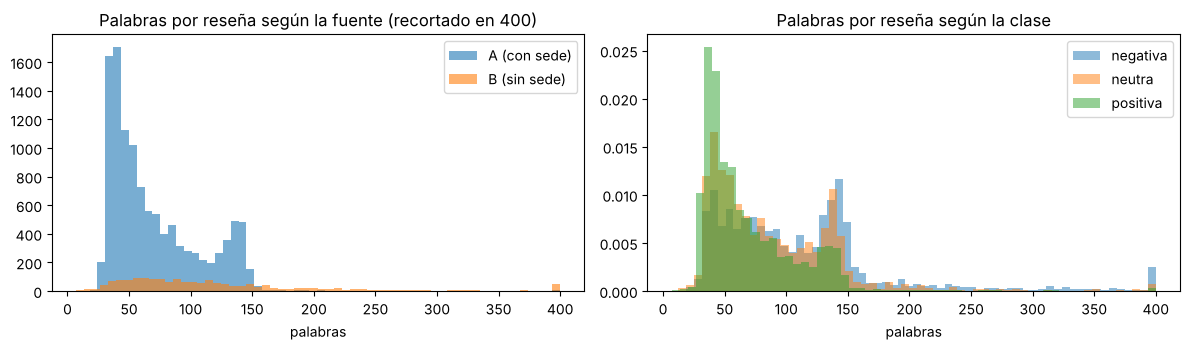

In [8]:
# 3.5 Longitud y reseñas cortadas en el origen
u['cortada'] = u.review_text.str.contains(r'…\s*$')
print('Reseñas que terminan en «…» por fuente (%):', u.groupby('fuente').cortada.mean().mul(100).round(1).to_dict())
print('Percentiles de palabras por reseña:', u.n_palabras.quantile([.5, .75, .9, .95, .99]).round(0).to_dict())
display(u.groupby('sentimiento').n_palabras.quantile([.5, .9, .95]).unstack().round(0))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for nombre, sub in u.groupby('fuente'):
    ax[0].hist(sub.n_palabras.clip(upper=400), bins=60, alpha=.6, label=nombre)
ax[0].set_title('Palabras por reseña según la fuente (recortado en 400)'); ax[0].set_xlabel('palabras'); ax[0].legend()
for clase in CLASES:
    ax[1].hist(u[u.sentimiento == clase].n_palabras.clip(upper=400), bins=60, alpha=.5, label=clase, density=True)
ax[1].set_title('Palabras por reseña según la clase'); ax[1].set_xlabel('palabras'); ax[1].legend()
plt.tight_layout(); guardar_figura('eda_longitud'); plt.show()

El **12,5 % de las reseñas de la fuente A termina en «…»**: el recolector las cortó y falta el final. Las negativas son las más largas (mediana de 98 palabras frente a 54 de las positivas): quien se queja explica más.
**Implicación:** si un modelo corta el texto, pierde primero las quejas. Esto fija la longitud de secuencia de la red (sección 8).

In [9]:
# 3.6 Idioma de cada reseña (langdetect con semilla fija)
t = time.perf_counter()
u['idioma'] = u.review_text.map(detectar_idioma)
print(f'Detección de idioma: {time.perf_counter() - t:.0f} s')
print('Reseñas por idioma:', u.idioma.value_counts().to_dict())
print(f'No español: {(u.idioma != "es").sum()} reseñas ({(u.idioma != "es").mean():.1%})')

Detección de idioma: 28 s
Reseñas por idioma: {'es': 13201, 'en': 58, 'fr': 24, 'it': 22, 'de': 6, 'nl': 5, 'pt': 5, 'ru': 3, 'tr': 3, 'ko': 1, 'sv': 1, 'fi': 1, 'ca': 1}
No español: 130 reseñas (1.0%)


130 reseñas (1,0 %) no están en español (58 en inglés, 24 en francés, 22 en italiano…).
**Decisión:** salen del entrenamiento y se guardan aparte para medir qué hace el modelo con un idioma que no conoce (sección 13).

In [10]:
# 3.7 Ruido de superficie y datos personales (PII)
patrones = {
    'URL': r'https?://\S+|www\.\S+', 'correo electrónico (PII)': r'[\w.%-]+@[\w.-]+\.[A-Za-z]{2,}',
    'teléfono (PII)': r'(?<!\d)(?:\+34[\s.-]?)?[6789]\d{2}[\s.-]?\d{3}[\s.-]?\d{3}(?!\d)',
    'texto mal codificado (Ã, Â)': r'Ã.|Â.|â€', 'emoji': '[\U0001F300-\U0001FAFF☀-➿]', 'signos repetidos (!!!, ???)': r'[!?]{3,}',
    'palabra en MAYÚSCULA sostenida': r'\b[A-ZÁÉÍÓÚÑ]{4,}\b', 'precios (€, euros)': r'€|\beuros?\b',
    '"@" de lenguaje inclusivo (chic@s)': r'\w@s?\b'}
ruido = pd.DataFrame({k: [u.review_text.str.contains(v, regex=True).sum(), u.review_text.str.contains(v, regex=True).mean() * 100]
                      for k, v in patrones.items()}, index=['reseñas', '% reseñas']).T
display(ruido.astype({'reseñas': int}).round({'% reseñas': 2}))
print(f'Títulos repetidos: {u.title.duplicated().mean():.1%} | los más comunes:', u.title.value_counts().head(5).to_dict())

,reseñas,% reseñas
URL,1,0.01
correo electrónico (PII),0,0.00
teléfono (PII),2,0.02
"texto mal codificado (Ã, Â)",0,0.00
emoji,139,1.04
"signos repetidos (!!!, ???)",467,3.50
palabra en MAYÚSCULA sostenida,784,5.88
"precios (€, euros)",966,7.25
"""@"" de lenguaje inclusivo (chic@s)",38,0.29


Títulos repetidos: 23.0% | los más comunes: {'Excelente': 186, 'Perfecto': 88, 'Muy recomendable': 70, 'Recomendable': 55, 'Buen hotel': 51}


Casi no hay datos de contacto: 0 correos, 2 teléfonos y 1 enlace. Sí hay señales de estilo que llevan sentimiento y por eso **no se borran**: emojis (1 %), signos repetidos (3,5 %), palabras en mayúscula sostenida (5,9 %) y la «@» del lenguaje inclusivo (chic@s), que la regla de correos respeta.
El riesgo de privacidad real son los **nombres de empleados y huéspedes** («gracias a Ana de recepción»): se tratan en la sección 6.

In [11]:
# 3.8 Sedes (hoteles) y ciudades (provincias): la base de la partición y del análisis por segmento
A_ = u[u.fuente.str.startswith('A')]
por_sede = A_.groupby('hotel').agg(n=('id', 'size'), pct_neg=('sentimiento', lambda s: (s == 'negativa').mean()))
print('Sedes:', len(por_sede), '| reseñas únicas por sede (mín / mediana / máx):', int(por_sede.n.min()), '/', int(por_sede.n.median()), '/', int(por_sede.n.max()))
peores = por_sede.sort_values('pct_neg', ascending=False).head(len(por_sede) // 10).index
print(f'El 10 % de sedes con más quejas concentra el {A_[A_.hotel.isin(peores)].sentimiento.eq("negativa").sum() / A_.sentimiento.eq("negativa").sum():.0%} de las reseñas negativas')
solo_letras = lambda s: re.sub(r'[\W_]+', ' ', s.lower()).strip()
print(f'Reseñas que mencionan el nombre completo de su sede: {A_.apply(lambda r: solo_letras(r.hotel) in solo_letras(r.review_text), axis=1).mean():.1%}')
PROVINCIAS = {'Seville': 'Sevilla', 'Granada': 'Granada', 'Cordoba': 'Córdoba', 'Malaga': 'Málaga', 'Almeria': 'Almería',
              'Jaen': 'Jaén', 'Huelva': 'Huelva', 'Cadiz': 'Cádiz'}
def provincia(loc):
    if not isinstance(loc, str): return 'sin dato (fuente B)'
    m = re.search(r'Province_of_([A-Za-z]+)', loc)
    if m: return next((v for k, v in PROVINCIAS.items() if k.startswith(m.group(1)) or m.group(1).startswith(k)), m.group(1))
    if 'Aracena' in loc: return 'Huelva'
    if 'Algarve' in loc: return 'Faro (Portugal)'
    return 'otra'
u['provincia'] = u.location.map(provincia)
print('Reseñas únicas por provincia:', u.provincia.value_counts().to_dict())

Sedes: 715 | reseñas únicas por sede (mín / mediana / máx): 1 / 20 / 20
El 10 % de sedes con más quejas concentra el 32% de las reseñas negativas


Reseñas que mencionan el nombre completo de su sede: 2.2%
Reseñas únicas por provincia: {'Sevilla': 3267, 'Granada': 2315, 'Córdoba': 2113, 'Málaga': 2002, 'sin dato (fuente B)': 1792, 'Almería': 914, 'Huelva': 512, 'Jaén': 376, 'Cádiz': 20, 'Faro (Portugal)': 20}


715 sedes, con un máximo de 20 reseñas únicas cada una (el recolector tomó 20 por hotel). **El 10 % de las sedes con más quejas concentra el 32 % de las negativas:** las alertas no se repartirán parejo; unas pocas sedes recibirán la mayoría.
El 2,2 % de las reseñas menciona el nombre completo de su sede. El modelo podría aprender «sede X = mala» en lugar de leer el texto; por eso el nombre se enmascara (sección 4).

### Hallazgos de la EDA que quedan fuera del alcance (backlog)
| Hallazgo | Por qué importa | Qué haría el equipo con datos de Bodytech |
|---|---|---|
| La etiqueta viene de las estrellas | 3★ mezcla textos muy distintos | Etiquetar a mano una muestra y medir el acuerdo entre personas |
| 12,5 % de reseñas cortadas en origen | Falta el final, que suele traer la conclusión | Pedir el texto completo a la fuente |
| Máximo 20 reseñas por sede | No hay historia larga por sede | Usar el histórico completo de la app, Google y encuestas |
| Dominio hotelero | El vocabulario de un gimnasio es otro (máquinas, clases, cupos) | Reentrenar con reseñas reales de Bodytech; la sección 13 estima la brecha |
| No hay fecha por reseña | No se puede partir por tiempo | Registrar la fecha y validar con una partición temporal |

## 4. Limpieza
Una sola función, `normalizar()` de `src/texto.py`, que usan por igual el entrenamiento, la evaluación y la demo:
- unifica la forma en que se guardan las letras con tilde (normalización **NFC**: «é» siempre es el mismo carácter, venga de donde venga);
- reemplaza enlaces, correos y teléfonos por marcadores (`[URL]`, `[EMAIL]`, `[TEL]`);
- quita la marca de corte «…» que dejó el recolector.

**No** se quitan tildes, mayúsculas ni signos, porque llevan sentimiento («PÉSIMO!!!»). Aparte, el nombre de la sede se reemplaza por `[SEDE]`.

In [12]:
# 4. Limpieza con reglas fijas (no aprenden de los datos, por eso van antes de partir)
datos = u[u.idioma == 'es'].copy().reset_index(drop=True)
otros_idiomas = u[u.idioma != 'es'].copy().reset_index(drop=True)          # se apartan; se usan en las pruebas de robustez

# Minimización: la sede se reemplaza por un código y la ubicación por la provincia
CODIGO_SEDE = {h: f'S{i:03d}' for i, h in enumerate(sorted(u.hotel.dropna().unique()), 1)}
for tabla in (datos, otros_idiomas):
    tabla['sede_id'] = tabla.hotel.map(CODIGO_SEDE).fillna('sin_sede')
    tabla['titulo'] = tabla.title.map(normalizar)
    tabla['resena'] = tabla.review_text.map(normalizar)
    # El nombre de la propia sede se reemplaza por [SEDE]: el modelo no debe juzgar por la reputación del lugar
    tabla['titulo'] = [enmascarar_sede(t, h) if isinstance(h, str) else t for t, h in zip(tabla.titulo, tabla.hotel)]
    tabla['resena'] = [enmascarar_sede(t, h) if isinstance(h, str) else t for t, h in zip(tabla.resena, tabla.hotel)]

marcadores = {m: int(datos.resena.str.contains(re.escape(m)).sum() + datos.titulo.str.contains(re.escape(m)).sum())
              for m in ['[URL]', '[EMAIL]', '[TEL]', '[SEDE]']}
print('Archivo original:', len(df), '→ sin duplicados:', len(u), '→ solo español:', len(datos))
print('Reseñas con cada marcador después de limpiar:', marcadores)
ej = datos[datos.resena.str.contains('[SEDE]', regex=False)].iloc[0]
print('\nEjemplo de sede enmascarada:', ej.resena[:200])

Archivo original: 18172 → sin duplicados: 13331 → solo español: 13201
Reseñas con cada marcador después de limpiar: {'[URL]': 1, '[EMAIL]': 0, '[TEL]': 2, '[SEDE]': 349}

Ejemplo de sede enmascarada: El Hotel [SEDE] es un hotel muy recomendable con una envidiable localización en el casco antiguo de Sevilla, a 7 minutos a pie de La Giralda. Es un precioso edificio antiguo rehabilitado y muy Moderno


De 18.172 filas se pasa a 13.331 sin duplicados y a 13.201 en español. El nombre de la sede se enmascaró en 349 reseñas.

## 5. Partición sin fuga: cada sede entera en una sola parte
Si reseñas de la misma sede quedan en train y en test, el modelo puede aprender rasgos de esa sede (su nombre, su barrio, sus problemas de siempre) y el test deja de medir lo que importa: **cómo le irá en una sede nueva**. Por eso la partición es por sede (`GroupShuffleSplit`, eligiendo entre 200 intentos el que mejor conserva la proporción de clases): 25 % de las sedes para test y, del resto, 20 % para validación. La fuente B queda aparte como prueba externa.

In [13]:
# 5. Partición sin fuga: todas las reseñas de una sede quedan en la misma parte
A = datos[datos.fuente.str.startswith('A')].reset_index(drop=True)
B = datos[datos.fuente.str.startswith('B')].reset_index(drop=True)
i_dev, i_test = partir_por_grupo(A, 0.25, grupo='sede_id', clases=CLASES, semilla=SEED)          # 25 % de las sedes para test
j_train, j_val = partir_por_grupo(A.iloc[i_dev], 0.20, grupo='sede_id', clases=CLASES, semilla=SEED)   # 20 % del resto para validación
A['parte'] = 'test'; A.loc[i_dev[j_train], 'parte'] = 'train'; A.loc[i_dev[j_val], 'parte'] = 'val'
B['parte'] = 'externo'                                    # fuente B: prueba externa, nunca se entrena con ella
otros_idiomas['parte'] = 'otro_idioma'
datos = pd.concat([A, B], ignore_index=True)

resumen = pd.crosstab(datos.parte, datos.sentimiento, normalize='index').mul(100).round(1)
resumen.insert(0, 'reseñas', datos.parte.value_counts())
resumen['sedes'] = datos[datos.sede_id != 'sin_sede'].groupby('parte').sede_id.nunique()
display(resumen.loc[['train', 'val', 'test', 'externo']].fillna('—'))
partes = {p: set(datos[datos.parte == p].sede_id) for p in ['train', 'val', 'test']}
print('Sedes compartidas → train∩test:', len(partes['train'] & partes['test']), '| train∩val:', len(partes['train'] & partes['val']),
      '| val∩test:', len(partes['val'] & partes['test']))

sentimiento,reseñas,negativa,neutra,positiva,sedes
parte,,,,,
train,6873,13.4,12.7,73.9,421.0
val,1710,13.7,12.6,73.7,106.0
test,2827,13.4,12.6,73.9,176.0
externo,1791,27.9,15.9,56.2,—


Sedes compartidas → train∩test: 0 | train∩val: 0 | val∩test: 0


Train 6.873 reseñas (421 sedes), validación 1.710 (106 sedes) y test 2.827 (176 sedes), con la misma mezcla de clases en las tres (≈13 % de negativas). **Ninguna sede aparece en dos partes.** La prueba externa tiene 1.791 reseñas.

## 6. Anonimización de nombres y corpus que se entrega
Los nombres de empleados y huéspedes son datos personales. Se reemplazan por `[NOMBRE]` con el reconocedor de entidades de spaCy (`es_core_news_sm`) más una regla de precisión: una palabra con mayúscula inicial solo se enmascara si **nunca aparece en minúscula en train** (así «Excelente» al comienzo de una frase no se toma por un nombre). Ese léxico se aprende **solo con train y después de partir**, para no usar información de validación ni de test.

In [14]:
# 6. Anonimización de nombres de personas (después de partir: el léxico se aprende SOLO con train)
textos_train = (datos[datos.parte == 'train'].titulo + '. ' + datos[datos.parte == 'train'].resena).tolist()
LEXICO = construir_lexico(textos_train)                  # palabras que en train aparecen en minúscula: son comunes, no nombres
# Las provincias no se enmascaran (el reconocedor a veces las marca como persona); los nombres de sedes ya son [SEDE]
EXCLUIR = sorted({p.lower() for p in PROVINCIAS.values()} | {sin_tildes(p).lower() for p in PROVINCIAS.values()} | {'andalucía', 'andalucia', 'españa'})
anon = Anonimizador(LEXICO, excluir=EXCLUIR)
t = time.perf_counter()
for tabla in (datos, otros_idiomas):
    tit, n_t, p_t = anon.enmascarar(tabla.titulo.tolist())
    res, n_r, p_r = anon.enmascarar(tabla.resena.tolist())
    tabla['titulo'], tabla['resena'] = tit, res
    tabla['n_nombres_enmascarados'] = np.array(n_t) + np.array(n_r)
    tabla['_palabras'] = [a + b for a, b in zip(p_t, p_r)]
print(f'Anonimización de {len(datos) + len(otros_idiomas)} reseñas: {time.perf_counter() - t:.0f} s | léxico de train: {len(LEXICO)} palabras')
con_nombre = datos.n_nombres_enmascarados > 0
print(f'Reseñas con al menos un nombre enmascarado: {con_nombre.sum()} ({con_nombre.mean():.1%})')
print('Palabras enmascaradas más frecuentes:', collections.Counter(w for ps in datos._palabras for w in ps).most_common(25))
muestra_anon = datos[con_nombre].sample(40, random_state=SEED)
def contexto(r):
    w = r._palabras[0]; texto = (r.title + '. ' + r.review_text); i = texto.find(w)
    return texto[max(0, i - 60): i + 50].replace('\n', ' ')
print('\nMuestra de 40 reseñas para revisar a mano (palabras enmascaradas | contexto original):')
for _, r in muestra_anon.iterrows(): print(f'  {r._palabras} | …{contexto(r)}…')

Anonimización de 13331 reseñas: 62 s | léxico de train: 9010 palabras
Reseñas con al menos un nombre enmascarado: 1631 (12.4%)
Palabras enmascaradas más frecuentes: [('José', 65), ('Manuel', 59), ('Antonio', 47), ('María', 46), ('Ana', 43), ('Juan', 39), ('Jose', 33), ('Cristina', 28), ('Javier', 27), ('Pedro', 26), ('Carlos', 25), ('Enrique', 24), ('Gerardo', 24), ('Miguel', 23), ('Rocío', 22), ('Fernando', 19), ('Angel', 19), ('Nick', 19), ('Emilio', 18), ('Luis', 18), ('Martin', 18), ('Carlo', 18), ('Zambrano', 18), ('Jody', 17), ('Diego', 16)]

Muestra de 40 reseñas para revisar a mano (palabras enmascaradas | contexto original):
  ['Keith'] | …o para usted. Piscina, sala de deportes, gimnasio. El dueño Keith le recogerá en el aeropuerto de Granada y ha…
  ['Brigitte', 'Roger', 'Roger'] | … tuvo unas excelentes vacaciones en este maravilloso lugar! Brigitte y Roger nos recibieron cálidamente. ¡Prob…
  ['Rechazamos'] | …ucias era una anécdota k sólo nos había pasado a nosotras!! Rec

**1.631 reseñas (12,4 %) tenían al menos un nombre.** Los más enmascarados son nombres de pila (José, Manuel, Antonio, María…).
La muestra para revisar a mano muestra el balance: acierta en la mayoría (Keith, Brigitte, Roger, Ana, Rocío, Raquel), pero también enmascara algunos verbos al comienzo de una frase («Rechazamos», «Desearía»), lugares («Cazorla») y marcas («Cope»). **Se acepta ese error porque es preferible borrar de más que dejar un nombre**; el costo es perder alguna palabra. La revisión humana de una muestra del corpus queda como control en la matriz de riesgos.

In [15]:
# Corpus anonimizado: es el dataset que se entrega y el que usan todos los modelos (incluido BETO, notebook 02)
datos['texto'] = datos.titulo + '. ' + datos.resena                      # entrada del modelo: título + reseña
otros_idiomas['texto'] = otros_idiomas.titulo + '. ' + otros_idiomas.resena
COLUMNAS = ['id', 'fuente', 'sede_id', 'provincia', 'rating', 'sentimiento', 'titulo', 'resena', 'texto', 'idioma', 'cortada',
            'n_nombres_enmascarados', 'parte']
corpus = pd.concat([datos, otros_idiomas], ignore_index=True)[COLUMNAS].rename(columns={'cortada': 'cortada_en_origen'})
corpus['fuente'] = corpus.fuente.str[0]
corpus.to_csv(config.RUTA_CORPUS, index=False, encoding='utf-8')
DICCIONARIO = {
    'id': ('entero', 'Identificador de la fila en el archivo original Big_AHR.csv (trazabilidad)'),
    'fuente': ('texto', 'A = reseñas de TripAdvisor con sede identificada; B = reseñas sin sede (corpus COAH), usadas como prueba externa'),
    'sede_id': ('texto', 'Código seudónimo de la sede (S001…); sin_sede en la fuente B'),
    'provincia': ('texto', 'Provincia de la sede (en Bodytech: la ciudad)'),
    'rating': ('entero', 'Calificación de 1 a 5 estrellas (no es entrada del modelo)'),
    'sentimiento': ('texto', 'Etiqueta: negativa (1-2★), neutra (3★), positiva (4-5★)'),
    'titulo': ('texto', 'Título limpio y anonimizado'), 'resena': ('texto', 'Reseña limpia y anonimizada'),
    'texto': ('texto', 'Entrada de los modelos: título + ". " + reseña'),
    'idioma': ('texto', 'Idioma detectado (langdetect)'), 'cortada_en_origen': ('booleano', 'La reseña original terminaba en «…» (texto incompleto)'),
    'n_nombres_enmascarados': ('entero', 'Cantidad de nombres de personas reemplazados por [NOMBRE]'),
    'parte': ('texto', 'train, val, test (fuente A, partición por sede), externo (fuente B) u otro_idioma (excluida del entrenamiento)')}
dic = pd.DataFrame([{'columna': c, 'tipo': t, 'descripción': d, 'nulos': int(corpus[c].isna().sum())} for c, (t, d) in DICCIONARIO.items()])
dic.to_csv(config.RUTA_CORPUS.parent / 'diccionario_datos.csv', index=False, encoding='utf-8')
config.RUTA_LEXICO.write_text('\n'.join(LEXICO), encoding='utf-8')
print(f'Corpus guardado: {config.RUTA_CORPUS.relative_to(RAIZ)} · {len(corpus)} filas · {config.RUTA_CORPUS.stat().st_size / 1e6:.1f} MB')
display(dic)
print('Filas por parte:', corpus.parte.value_counts().to_dict())

Corpus guardado: datos/procesado/corpus_bodytech_anonimizado.csv · 13331 filas · 13.8 MB


,columna,tipo,descripción,nulos
0,id,entero,Identificador de la fila en el archivo original Big_AHR.csv (trazabilidad),0
1,fuente,texto,"A = reseñas de TripAdvisor con sede identificada; B = reseñas sin sede (corpus COAH), usadas como prueba externa",0
2,sede_id,texto,Código seudónimo de la sede (S001…); sin_sede en la fuente B,0
3,provincia,texto,Provincia de la sede (en Bodytech: la ciudad),0
4,rating,entero,Calificación de 1 a 5 estrellas (no es entrada del modelo),0
5,sentimiento,texto,"Etiqueta: negativa (1-2★), neutra (3★), positiva (4-5★)",0
6,titulo,texto,Título limpio y anonimizado,0
7,resena,texto,Reseña limpia y anonimizada,0
8,texto,texto,"Entrada de los modelos: título + "". "" + reseña",0
9,idioma,texto,Idioma detectado (langdetect),0


Filas por parte: {'train': 6873, 'test': 2827, 'externo': 1791, 'val': 1710, 'otro_idioma': 130}


El corpus que se entrega, `datos/procesado/corpus_bodytech_anonimizado.csv` (13.331 filas, 13,8 MB), ya viene sin duplicados, limpio, anonimizado y con la partición en la columna `parte`. La sede es un código (S001…), no el nombre del hotel. El diccionario de datos está en `datos/procesado/diccionario_datos.csv`. BETO (notebook 02) usa este mismo archivo.

In [16]:
# ¿Qué habría pasado con la partición "de siempre": aleatoria sobre el archivo tal como llega?
f1m = lambda y, p: f1_score(y, p, average='macro')
recall_critico = lambda y, p: recall_score(y, p, labels=[CLASE_CRITICA], average=None)[0]
crudo = df.review_text.map(normalizar)
Xtr0, Xte0, ytr0, yte0 = train_test_split(crudo, df.sentimiento, test_size=.25, random_state=SEED, stratify=df.sentimiento)
ya_vista = Xte0.isin(set(Xtr0)).values
pred0 = crear_baseline(SEED).fit(Xtr0, ytr0).predict(Xte0)
train, val, test, externo = [datos[datos.parte == p].reset_index(drop=True) for p in ['train', 'val', 'test', 'externo']]
dev = pd.concat([train, val], ignore_index=True)
pred_limpio = crear_baseline(SEED).fit(train.resena, train.sentimiento).predict(val.resena)
display(pd.DataFrame([
    dict(evaluación='Archivo crudo, partición aleatoria', n=len(yte0), F1_macro=f1m(yte0, pred0), recall_negativa=recall_critico(yte0, pred0)),
    dict(evaluación='   · filas de test que ya estaban en train', n=ya_vista.sum(), F1_macro=f1m(yte0[ya_vista], pred0[ya_vista]), recall_negativa=recall_critico(yte0[ya_vista], pred0[ya_vista])),
    dict(evaluación='   · filas de test realmente nuevas', n=(~ya_vista).sum(), F1_macro=f1m(yte0[~ya_vista], pred0[~ya_vista]), recall_negativa=recall_critico(yte0[~ya_vista], pred0[~ya_vista])),
    dict(evaluación='Corpus limpio, partición por sede (validación)', n=len(val), F1_macro=f1m(val.sentimiento, pred_limpio), recall_negativa=recall_critico(val.sentimiento, pred_limpio)),
]).set_index('evaluación').round(3))
print(f'En la partición aleatoria del archivo crudo, el {ya_vista.mean():.1%} de las filas de test ya estaba en train.')

,n,F1_macro,recall_negativa
evaluación,,,
"Archivo crudo, partición aleatoria",4543,0.802,0.891
· filas de test que ya estaban en train,1696,0.963,0.995
· filas de test realmente nuevas,2847,0.721,0.842
"Corpus limpio, partición por sede (validación)",1710,0.728,0.825


En la partición aleatoria del archivo crudo, el 37.3% de las filas de test ya estaba en train.


**Cuánto engaña una partición descuidada.** Con el archivo tal como llega y una partición al azar, el mismo baseline (ambos con solo el texto de la reseña) obtiene **F1 macro 0,802**. Pero el **37,3 % de las filas de test ya estaba en train** (copias) y en ellas el F1 es 0,963; en las filas realmente nuevas baja a 0,721. Con el corpus limpio y la partición por sede, el F1 de validación es **0,728**. La partición descuidada inflaba el resultado en unos 7 puntos.

## 7. Baseline: TF-IDF + regresión logística
El baseline es fuerte a propósito: si un modelo avanzado no le gana, no vale su costo. Primero se prueban decisiones de preprocesamiento **una por una** (pruebas A/B) con validación cruzada de 5 pliegues agrupada por sede, sobre train + validación. Después se entrena el baseline final solo con train.

In [17]:
# 7.1 Pruebas A/B del baseline: cada fila cambia UNA decisión. Validación cruzada de 5 pliegues agrupada por sede (sobre train + val).
from spacy.lang.es.stop_words import STOP_WORDS
PROTEGIDAS = {'no', 'ni', 'nada', 'nunca', 'sin', 'tampoco', 'pero', 'aunque', 'muy', 'poco', 'mucho', 'más', 'menos', 'demasiado',
              'bastante', 'casi', 'solo', 'todo', 'bien', 'mal', 'buen', 'bueno', 'buena', 'mejor', 'peor', 'ningún', 'ninguna', 'ninguno', 'sí'}
pliegues = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(dev.texto, dev.sentimiento, groups=dev.sede_id))

def evaluar_cv(nombre, textos, class_weight='balanced', **tfidf):
    modelo = crear_baseline(SEED, class_weight=class_weight, **tfidf)
    t = time.perf_counter(); pred = cross_val_predict(modelo, textos, dev.sentimiento, cv=pliegues)
    por_pliegue = [f1m(dev.sentimiento.iloc[te], pred[te]) for _, te in pliegues]
    f1c = f1_score(dev.sentimiento, pred, average=None, labels=CLASES)
    return dict(variante=nombre, F1_macro=f1m(dev.sentimiento, pred), desv_pliegues=np.std(por_pliegue),
                recall_negativa=recall_critico(dev.sentimiento, pred), F1_negativa=f1c[0], F1_neutra=f1c[1], F1_positiva=f1c[2],
                segundos=time.perf_counter() - t)

ab = pd.DataFrame([
    evaluar_cv('BASE: palabras 1-2, título + reseña, balanceado', dev.texto),
    evaluar_cv('Caracteres 3-5 (char_wb)', dev.texto, analyzer='char_wb', ngram_range=(3, 5)),
    evaluar_cv('Sin título (solo la reseña)', dev.resena),
    evaluar_cv('Quitar stopwords (lista completa de spaCy)', dev.texto, stop_words=sorted(STOP_WORDS)),
    evaluar_cv('Quitar stopwords pero conservar negación y valoración', dev.texto, stop_words=sorted(STOP_WORDS - PROTEGIDAS)),
    evaluar_cv('Solo unigramas', dev.texto, ngram_range=(1, 1)),
    evaluar_cv('Sin balancear clases', dev.texto, class_weight=None),
]).set_index('variante')
ab.insert(1, 'dif_vs_base', ab.F1_macro - ab.F1_macro.iloc[0])
display(ab.round(3))
pred_azar = cross_val_predict(crear_baseline(SEED), dev.texto, dev.sentimiento, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
print(f'Misma base con pliegues al azar (sin agrupar por sede): F1 macro {f1m(dev.sentimiento, pred_azar):.3f} | agrupando por sede: {ab.F1_macro.iloc[0]:.3f}')

,F1_macro,dif_vs_base,desv_pliegues,recall_negativa,F1_negativa,F1_neutra,F1_positiva,segundos
variante,,,,,,,,
"BASE: palabras 1-2, título + reseña, balanceado",0.740,0.000,0.008,0.831,0.787,0.511,0.921,5.692
Caracteres 3-5 (char_wb),0.734,-0.006,0.008,0.833,0.783,0.502,0.916,22.360
Sin título (solo la reseña),0.721,-0.019,0.011,0.819,0.771,0.477,0.915,5.639
Quitar stopwords (lista completa de spaCy),0.727,-0.012,0.006,0.806,0.769,0.494,0.920,3.836
Quitar stopwords pero conservar negación y valoración,0.752,0.012,0.006,0.828,0.797,0.533,0.925,4.359
Solo unigramas,0.729,-0.011,0.006,0.834,0.778,0.496,0.912,2.805
Sin balancear clases,0.665,-0.074,0.011,0.731,0.778,0.296,0.923,6.599


Misma base con pliegues al azar (sin agrupar por sede): F1 macro 0.739 | agrupando por sede: 0.740


**Qué decisiones se sostienen con evidencia:**
- **Balancear las clases es la decisión que más pesa:** sin ella el F1 macro cae 0,074 y la neutra casi desaparece (F1 0,296).
- **El título ayuda** (+0,019 frente a usar solo la reseña): «Pésimo» o «Excelente» resumen la opinión.
- **Quitar todas las *stopwords* empeora** (−0,012) porque la lista de spaCy incluye «no», «pero» y «muy». Quitarlas conservando negación y valoración mejora +0,012; no se adopta porque se exige a cualquier cambio el mismo +0,02 que al modelo avanzado y porque agrega una lista hecha a mano que habría que mantener. Queda como mejora candidata.
- **Los bigramas aportan** (+0,011 frente a solo palabras sueltas): «no recomiendo», «muy bien».
- **Los n-gramas de caracteres no mejoran** (−0,006) y son 4 veces más lentos.
- Con pliegues al azar el resultado casi no cambia (0,739 frente a 0,740): quitados los duplicados, la fuga restante es pequeña. Igual se agrupa por sede, porque así se usará el sistema.

In [18]:
# 7.2 Baseline final: TF-IDF + regresión logística, entrenado SOLO con train y evaluado en validación
t = time.perf_counter(); base = crear_baseline(SEED).fit(train.texto, train.sentimiento); seg_base = time.perf_counter() - t
assert list(base.classes_) == CLASES
base_prob_val = base.predict_proba(val.texto); base_pred_val = base.classes_[base_prob_val.argmax(1)]
print(classification_report(val.sentimiento, base_pred_val, digits=3))
print(f'F1 macro (validación): {f1m(val.sentimiento, base_pred_val):.3f} | log loss: {log_loss(val.sentimiento, base_prob_val, labels=CLASES):.3f} '
      f'| términos: {len(base.named_steps["tfidf"].vocabulary_)} | entrenamiento: {seg_base:.1f} s')
joblib.dump(base, config.RUTA_BASELINE)
print('Guardado:', config.RUTA_BASELINE.relative_to(RAIZ), f'({config.RUTA_BASELINE.stat().st_size / 1e6:.1f} MB)')
terminos = np.array(base.named_steps['tfidf'].get_feature_names_out()); coefs = base.named_steps['clf'].coef_
print('\nTérminos con mayor peso por clase:')
display(pd.DataFrame({c: terminos[np.argsort(coefs[i])[::-1][:12]] for i, c in enumerate(CLASES)}))

              precision    recall  f1-score   support

    negativa      0.780     0.850     0.814       234
      neutra      0.500     0.579     0.536       216
    positiva      0.954     0.912     0.932      1260

    accuracy                          0.861      1710
   macro avg      0.745     0.780     0.761      1710
weighted avg      0.873     0.861     0.866      1710

F1 macro (validación): 0.761 | log loss: 0.452 | términos: 50885 | entrenamiento: 1.3 s
Guardado: modelos/baseline_tfidf_lr.joblib (2.5 MB)

Términos con mayor peso por clase:


,negativa,neutra,positiva
0,no,pero,muy
1,ni,bien,excelente
2,que,normal,todo
3,mal,correcto,recomendable
4,mala,bastante,muy bien
5,pésimo,normalito,perfecto
6,peor,aceptable,genial
7,no lo,está,buen
8,se,necesita,nombre
9,horrible,falta,gracias


En validación: **F1 macro 0,761** y recall de negativas 0,850. La neutra es la clase débil (F1 0,536). Entrena en 1,2 s y pesa 2,5 MB.
Los términos con más peso tienen sentido y se pueden explicar: «no», «ni», «mal», «pésimo» para negativa; «pero», «normal», «correcto», «mejorable» para neutra; «excelente», «recomendable», «perfecto» para positiva. Esos pesos son la **evidencia** que muestra la demo. Un detalle: «nombre» (el marcador `[NOMBRE]`) aparece entre los términos positivos, porque quien nombra a un empleado casi siempre es para agradecerle.

## 8. Modelo avanzado: BiLSTM
La red lee la reseña en orden, en los dos sentidos, y puede captar lo que TF-IDF ignora: el orden de las palabras («no es bueno, es malo») y el alcance de una negación. Se comparan dos variantes con el mismo presupuesto: embedding iniciado **al azar** y embedding iniciado con **Word2Vec** entrenado solo con train. Cada variante se entrena con **5 semillas** para separar una mejora real del azar.

In [19]:
# 8.1 De texto a secuencias: tamaño del vocabulario y longitud máxima, decididos con train
for parte in (train, val, test, externo, dev):
    parte['seq'] = parte.texto.map(a_secuencia); parte['n_tokens'] = parte.seq.str.split().str.len()
frec = collections.Counter(w for s in train.seq for w in s.split()); orden = [w for w, _ in frec.most_common()]
def tasa_oov(seqs, vocab):
    toks = [w for s in seqs for w in s.split()]; return sum(w not in vocab for w in toks) / len(toks)
filas = []
for V in [5000, 10000, 15000, len(frec) + 2]:
    vocab = set(orden[:V - 2])
    filas.append({'MAX_TOKENS': V, 'OOV train %': tasa_oov(train.seq, vocab) * 100, 'OOV val %': tasa_oov(val.seq, vocab) * 100,
                  'parámetros del embedding': V * PRESUPUESTO['embed_dim']})
display(pd.DataFrame(filas).set_index('MAX_TOKENS').round(1))
filas = []
for L in [40, 100, 160, 200, 300]:
    filas.append({'SEQ_LEN': L, 'train truncadas %': (train.n_tokens > L).mean() * 100,
                  'negativas truncadas %': (train[train.sentimiento == 'negativa'].n_tokens > L).mean() * 100,
                  'tokens perdidos %': (train.n_tokens - L).clip(lower=0).sum() / train.n_tokens.sum() * 100})
display(pd.DataFrame(filas).set_index('SEQ_LEN').round(1))

le = LabelEncoder().fit(CLASES)
ytr_i, yval_i, yte_i, yext_i = [le.transform(p.sentimiento) for p in (train, val, test, externo)]
MAX_TOKENS, SEQ_LEN, EMBED_DIM = 10000, 160, PRESUPUESTO['embed_dim']
tv = tf.keras.layers.TextVectorization(max_tokens=MAX_TOKENS, standardize=None, split='whitespace', output_mode='int', output_sequence_length=SEQ_LEN)
tv.adapt(tf.data.Dataset.from_tensor_slices(train.seq.tolist()).batch(64))          # el vocabulario se aprende SOLO con train
a_matriz = lambda parte: tv(tf.constant(parte.seq.tolist())).numpy()
Xtr_s, Xval_s, Xte_s, Xext_s = [a_matriz(p) for p in (train, val, test, externo)]
for nombre, X in [('train', Xtr_s), ('val', Xval_s), ('test', Xte_s), ('externo', Xext_s)]:
    print(f'{nombre:8s} OOV: {(X == 1).sum() / (X != 0).sum():.1%} | relleno (PAD): {(X == 0).mean():.1%} de las posiciones')

,OOV train %,OOV val %,parámetros del embedding
MAX_TOKENS,,,
5000,4.3,5.2,320000
10000,1.8,3.1,640000
15000,0.8,2.5,960000
19172,0.0,2.1,1227008


,train truncadas %,negativas truncadas %,tokens perdidos %
SEQ_LEN,,,
40,83.8,94.4,47.0
100,23.6,46.3,10.8
160,0.8,3.5,0.8
200,0.4,1.3,0.5
300,0.1,0.5,0.2


train    OOV: 1.8% | relleno (PAD): 53.8% de las posiciones
val      OOV: 3.0% | relleno (PAD): 52.2% de las posiciones
test     OOV: 3.0% | relleno (PAD): 54.2% de las posiciones
externo  OOV: 4.4% | relleno (PAD): 33.9% de las posiciones


**Vocabulario de 10.000 palabras:** deja 3,1 % de palabras desconocidas en validación; subir a 15.000 solo las baja a 2,5 % y agrega 320.000 parámetros.
**Longitud de 160 tokens:** con 100 se cortaría el 46 % de las negativas (las quejas son largas); con 160, solo el 3,5 %.
La prueba externa tiene más palabras desconocidas (4,4 %): es la primera señal de un cambio de distribución.

In [20]:
# 8.2 Word2Vec entrenado SOLO con train: vectores iniciales para el embedding de la red
import hashlib
from gensim.models import Word2Vec
hash_fijo = lambda s: int(hashlib.md5(s.encode('utf-8')).hexdigest()[:8], 16)        # hash estable: mismos vectores en cada ejecución
t = time.perf_counter()
w2v = Word2Vec(sentences=[s.split() for s in train.seq], vector_size=EMBED_DIM, window=5, min_count=2, sg=1, epochs=5,
               workers=1, seed=SEED, hashfxn=hash_fijo)
print(f'Word2Vec: {len(w2v.wv)} palabras en {time.perf_counter() - t:.0f} s')
for palabra in ['sucio', 'amable', 'ruido']:
    print(f'  vecinos de «{palabra}»:', [w for w, _ in w2v.wv.most_similar(palabra, topn=6)])
vocab_tv = [str(w) for w in tv.get_vocabulary()]
E_w2v = np.random.default_rng(SEED).uniform(-.05, .05, (len(vocab_tv), EMBED_DIM)).astype('float32')
conocidas = [i for i, w in enumerate(vocab_tv) if w in w2v.wv.key_to_index]
E_w2v[conocidas] = w2v.wv[[vocab_tv[i] for i in conocidas]]; E_w2v[0] = 0
print(f'{len(conocidas)} de {len(vocab_tv)} palabras del vocabulario de la red tienen vector de Word2Vec')

Word2Vec: 9795 palabras en 6 s
  vecinos de «sucio»: ['roto', 'suciedad', 'polvo', 'humedades', 'mampara', 'wc']
  vecinos de «amable»: ['atento', 'simpático', 'servicial', 'profesional', 'eficiente', 'simpatico']
  vecinos de «ruido»: ['escucha', 'oye', 'oía', 'escuchaba', 'ruidosa', 'pasillo']
9795 de 10000 palabras del vocabulario de la red tienen vector de Word2Vec


Word2Vec aprende con train relaciones útiles: los vecinos de «sucio» son «roto», «suciedad» y «polvo»; los de «amable», «atento», «simpático» y «servicial». El 98 % del vocabulario de la red (9.795 de 10.000 palabras) recibe un vector inicial.

In [21]:
# 8.3 BiLSTM many-to-one: Embedding (mask_zero) → BiLSTM → Dropout → Softmax. Dos variantes, 5 semillas cada una.
pesos = compute_class_weight('balanced', classes=np.arange(len(CLASES)), y=ytr_i); PESOS_CLASE = dict(enumerate(pesos))

def metricas(y, prob):
    pred = prob.argmax(1)
    return dict(f1_macro=f1_score(y, pred, average='macro'), recall_critico=recall_score(y, pred, labels=[0], average=None)[0],
                f1_neutra=f1_score(y, pred, labels=[1], average=None)[0], log_loss=log_loss(y, prob, labels=[0, 1, 2]))

def crear_bilstm(pesos_embedding=None):
    inp = tf.keras.Input((SEQ_LEN,), dtype='int64')
    emb = tf.keras.layers.Embedding(len(vocab_tv), EMBED_DIM, mask_zero=True)
    x = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(PRESUPUESTO['units'], dropout=PRESUPUESTO['dropout']))(emb(inp))
    x = tf.keras.layers.Dropout(PRESUPUESTO['dropout'])(x)
    m = tf.keras.Model(inp, tf.keras.layers.Dense(len(CLASES), activation='softmax')(x))
    if pesos_embedding is not None: emb.set_weights([pesos_embedding])
    m.compile(optimizer=tf.keras.optimizers.Adam(PRESUPUESTO['lr'], clipnorm=1.0), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

REGISTRO, PROBS, HIST, MEJOR = [], {}, {}, {}
VARIANTES = {'bilstm': None, 'bilstm_w2v': E_w2v}
for nombre, E in VARIANTES.items():
    for seed in SEMILLAS:
        tf.keras.utils.set_random_seed(seed)
        m = crear_bilstm(E)
        cb = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PRESUPUESTO['paciencia'], restore_best_weights=True)]
        t = time.perf_counter()
        h = m.fit(Xtr_s, ytr_i, validation_data=(Xval_s, yval_i, pesos[yval_i]), epochs=PRESUPUESTO['epochs'],
                  batch_size=PRESUPUESTO['batch_size'], verbose=0, callbacks=cb, class_weight=PESOS_CLASE)
        seg = time.perf_counter() - t
        pv = m.predict(Xval_s, verbose=0, batch_size=256)
        # test y externo se calculan ahora pero NO se miran hasta la sección 9 (una sola apertura del test)
        PROBS[(nombre, seed)] = {'val': pv, 'test': m.predict(Xte_s, verbose=0, batch_size=256), 'externo': m.predict(Xext_s, verbose=0, batch_size=256)}
        HIST[(nombre, seed)] = h.history
        mv = metricas(yval_i, pv)
        REGISTRO.append({'modelo': nombre, 'semilla': seed, 'f1_macro_val': mv['f1_macro'], 'recall_negativa_val': mv['recall_critico'],
                         'f1_neutra_val': mv['f1_neutra'], 'log_loss_val': mv['log_loss'], 'epocas': len(h.history['loss']),
                         'mejor_epoca': int(np.argmin(h.history['val_loss'])) + 1, 'segundos': seg, 'parametros': m.count_params(),
                         **{k: v for k, v in PRESUPUESTO.items()}, 'max_tokens': MAX_TOKENS, 'seq_len': SEQ_LEN,
                         'embedding_inicial': 'word2vec (train)' if E is not None else 'aleatorio', 'tensorflow': tf.__version__})
        if mv['f1_macro'] > MEJOR.get(nombre, (-1, None))[0]:
            MEJOR[nombre] = (mv['f1_macro'], seed, m)               # se conserva el mejor modelo de cada variante (por validación)
        else:
            del m
        gc.collect()
        print(f"{nombre:11s} semilla {seed} | F1 val {mv['f1_macro']:.3f} | recall negativa {mv['recall_critico']:.3f} | "
              f"{len(h.history['loss'])} épocas (mejor {REGISTRO[-1]['mejor_epoca']}) | {seg:.0f} s")
registro = pd.DataFrame(REGISTRO)
resumen_val = registro.groupby('modelo').agg(F1_val_media=('f1_macro_val', 'mean'), F1_val_desv=('f1_macro_val', 'std'),
                                             F1_val_min=('f1_macro_val', 'min'), F1_val_max=('f1_macro_val', 'max'),
                                             recall_negativa=('recall_negativa_val', 'mean'), mejor_epoca=('mejor_epoca', 'mean'),
                                             segundos=('segundos', 'mean'), parametros=('parametros', 'first'))
resumen_val.loc['tfidf_lr (baseline)'] = [f1m(val.sentimiento, base_pred_val), 0, f1m(val.sentimiento, base_pred_val), f1m(val.sentimiento, base_pred_val),
                                          recall_critico(val.sentimiento, base_pred_val), np.nan, seg_base,
                                          base.named_steps['clf'].coef_.size + len(CLASES)]
display(resumen_val.round(3).astype({'parametros': int}))

bilstm      semilla 42 | F1 val 0.745 | recall negativa 0.782 | 6 épocas (mejor 3) | 63 s


bilstm      semilla 1 | F1 val 0.708 | recall negativa 0.885 | 5 épocas (mejor 2) | 52 s


bilstm      semilla 2 | F1 val 0.751 | recall negativa 0.821 | 6 épocas (mejor 3) | 59 s


bilstm      semilla 3 | F1 val 0.715 | recall negativa 0.812 | 5 épocas (mejor 2) | 52 s


bilstm      semilla 4 | F1 val 0.732 | recall negativa 0.889 | 5 épocas (mejor 2) | 50 s


bilstm_w2v  semilla 42 | F1 val 0.754 | recall negativa 0.795 | 9 épocas (mejor 6) | 91 s


bilstm_w2v  semilla 1 | F1 val 0.763 | recall negativa 0.880 | 9 épocas (mejor 6) | 89 s


bilstm_w2v  semilla 2 | F1 val 0.728 | recall negativa 0.906 | 8 épocas (mejor 5) | 80 s


bilstm_w2v  semilla 3 | F1 val 0.721 | recall negativa 0.897 | 9 épocas (mejor 6) | 112 s


bilstm_w2v  semilla 4 | F1 val 0.748 | recall negativa 0.855 | 7 épocas (mejor 4) | 73 s


,F1_val_media,F1_val_desv,F1_val_min,F1_val_max,recall_negativa,mejor_epoca,segundos,parametros
modelo,,,,,,,,
bilstm,0.730,0.018,0.708,0.751,0.838,2.4,55.182,706435
bilstm_w2v,0.743,0.018,0.721,0.763,0.867,5.4,88.966,706435
tfidf_lr (baseline),0.761,0.000,0.761,0.761,0.850,NaN,1.327,152658


En validación, la BiLSTM con Word2Vec (**0,743 ± 0,018**) supera a la de embedding al azar (0,730 ± 0,018), pero **ninguna supera al baseline (0,761)**. La variación entre semillas es grande (de 0,708 a 0,751 con embedding al azar): casi del tamaño de la diferencia entre variantes. La red con Word2Vec aprovecha más épocas (mejor época 5,4 frente a 2,4) porque parte de vectores con sentido.

Modelo avanzado elegido en validación: bilstm_w2v (se despliega la semilla 1, la de mejor F1 de validación)
Registro de experimentos: resultados/registro_experimentos.csv (11 corridas)


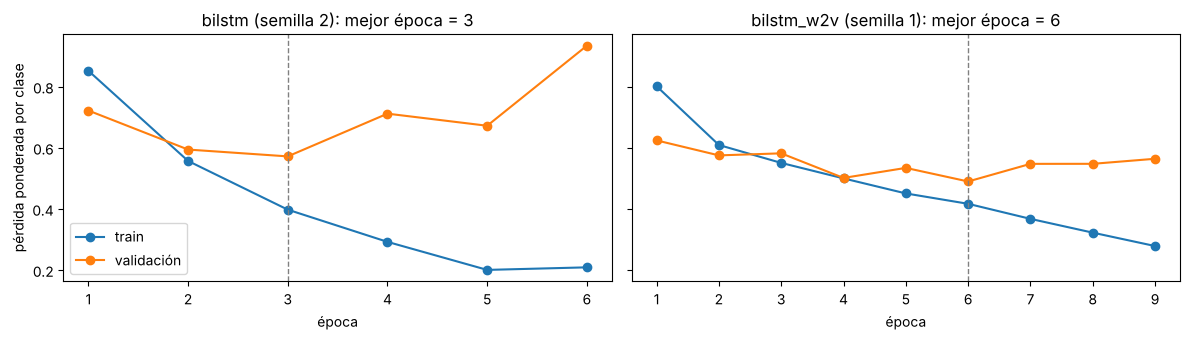

In [22]:
# 8.4 Selección con VALIDACIÓN, registro de experimentos y curvas de entrenamiento
AVANZADO = resumen_val.drop(index='tfidf_lr (baseline)').F1_val_media.idxmax()        # mejor variante por F1 medio de validación
SEMILLA_ELEGIDA = MEJOR[AVANZADO][1]
print(f'Modelo avanzado elegido en validación: {AVANZADO} (se despliega la semilla {SEMILLA_ELEGIDA}, la de mejor F1 de validación)')
registro_completo = pd.concat([pd.DataFrame([{'modelo': 'tfidf_lr', 'semilla': SEED, 'f1_macro_val': f1m(val.sentimiento, base_pred_val),
                                              'recall_negativa_val': recall_critico(val.sentimiento, base_pred_val), 'segundos': seg_base,
                                              'parametros': base.named_steps['clf'].coef_.size + len(CLASES), 'ngram_range': '(1, 2)', 'min_df': 2,
                                              'C': 1.0, 'class_weight': 'balanced', 'scikit-learn': sklearn.__version__}]), registro], ignore_index=True)
registro_completo.to_csv(config.DIR_RESULTADOS / 'registro_experimentos.csv', index=False)
print('Registro de experimentos:', (config.DIR_RESULTADOS / 'registro_experimentos.csv').relative_to(RAIZ), f'({len(registro_completo)} corridas)')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for a, nombre in zip(ax, VARIANTES):
    h = HIST[(nombre, MEJOR[nombre][1])]; ep = np.arange(1, len(h['loss']) + 1); mejor = int(np.argmin(h['val_loss'])) + 1
    a.plot(ep, h['loss'], marker='o', label='train'); a.plot(ep, h['val_loss'], marker='o', label='validación')
    a.axvline(mejor, ls='--', c='gray', lw=1); a.set_title(f'{nombre} (semilla {MEJOR[nombre][1]}): mejor época = {mejor}'); a.set_xlabel('época')
ax[0].set_ylabel('pérdida ponderada por clase'); ax[0].legend(); plt.tight_layout(); guardar_figura('curvas_bilstm'); plt.show()

Con la regla fijada de antemano (mejor F1 medio en validación) se elige **bilstm_w2v** y se despliega su semilla 1 (F1 de validación 0,763). Las curvas muestran que la pérdida de validación toca fondo en pocas épocas y luego sube: la parada temprana evita el sobreajuste. Las 11 corridas quedan en `resultados/registro_experimentos.csv` con hiperparámetros, tiempos y versiones.

## 9. Evaluación en test (se abre una sola vez)
Con los modelos y los umbrales ya elegidos en validación, se mide en test (sedes nunca vistas) y en la prueba externa (fuente B). Además de la calidad se mide lo que importa para operar: **calibración** (si la confianza que declara el modelo es real), **costo** (tiempo, tamaño, memoria) y **latencia**.

In [23]:
# 9. Evaluación en test (se abre UNA sola vez) y en la prueba externa: calidad, calibración, costo y latencia
BASE = 'tfidf_lr (baseline)'
red = MEJOR[AVANZADO][2]
servir = tf.function(lambda x: red(tv(x), training=False), input_signature=[tf.TensorSpec([None], tf.string)])   # inferencia compilada
P = {BASE: {'val': base_prob_val, 'test': base.predict_proba(test.texto), 'externo': base.predict_proba(externo.texto)}}
for nombre in VARIANTES: P[nombre] = PROBS[(nombre, MEJOR[nombre][1])]

def ece(y, prob, bins=10):
    """Error de calibración esperado: distancia promedio entre la confianza declarada y el acierto real (0 = perfecto)."""
    conf, ok, e = prob.max(1), prob.argmax(1) == y, 0.0
    for a, b in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > a) & (conf <= b)
        if m.any(): e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return e

def latencia_ms(predecir_uno, textos, n=200):
    predecir_uno(textos[0]); ts = []
    for t in textos[:n]:
        t0 = time.perf_counter(); predecir_uno(t); ts.append((time.perf_counter() - t0) * 1000)
    return np.percentile(ts, 50), np.percentile(ts, 95)

def rendimiento(predecir_lote, textos, lote=32, repeticiones=10):
    predecir_lote(textos[:lote]); t0 = time.perf_counter()
    for i in range(repeticiones): predecir_lote(textos[i * lote:(i + 1) * lote])
    return lote * repeticiones / (time.perf_counter() - t0)

MEDIR_PICO = r"""
import sys
try:                                   # Linux: pico de memoria de ESTE proceso (VmHWM, en kB); no hereda la memoria del notebook
    print(int([l for l in open('/proc/self/status') if l.startswith('VmHWM')][0].split()[1]) / 1024)
except OSError:                        # macOS: ru_maxrss viene en bytes (en Windows no hay medición y queda vacío)
    import resource; print(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024 ** 2)
"""
def memoria_proceso_mb(codigo):
    """Memoria máxima (MB) de un proceso nuevo que solo carga el modelo y clasifica una reseña."""
    try:
        r = subprocess.run([sys.executable, '-c', codigo + '\n' + MEDIR_PICO], capture_output=True, text=True, cwd=RAIZ, timeout=300,
                           env={**os.environ, 'TF_CPP_MIN_LOG_LEVEL': '3'})
        return float(r.stdout.strip().splitlines()[-1])
    except Exception:
        return np.nan

# Artefacto del modelo avanzado (para la memoria y para la demo)
config.DIR_RED.mkdir(parents=True, exist_ok=True)
red.save(config.DIR_RED / 'modelo.keras')
(config.DIR_RED / 'vocabulario.txt').write_text('\n'.join(vocab_tv), encoding='utf-8')
(config.DIR_RED / 'info.json').write_text(json.dumps({'variante': AVANZADO, 'semilla': SEMILLA_ELEGIDA, 'seq_len': SEQ_LEN, 'max_tokens': MAX_TOKENS,
                                                      'clases': CLASES, 'tensorflow': tf.__version__}, indent=2), encoding='utf-8')
tam_mb = lambda ruta: sum(f.stat().st_size for f in Path(ruta).rglob('*') if f.is_file()) / 1e6 if Path(ruta).is_dir() else Path(ruta).stat().st_size / 1e6

muestra_lat = test.texto.tolist()[:320]
pred_red = lambda textos: servir(tf.constant([a_secuencia(t) for t in textos])).numpy()
COSTO = {BASE: {'latencia': latencia_ms(lambda s: base.predict_proba([s]), muestra_lat), 'rendimiento': rendimiento(lambda xs: base.predict_proba(xs), muestra_lat),
                'tamaño (MB)': tam_mb(config.RUTA_BASELINE), 'parámetros': base.named_steps['clf'].coef_.size + len(CLASES), 'segundos': seg_base,
                'memoria (MB)': memoria_proceso_mb("import joblib; m = joblib.load('modelos/baseline_tfidf_lr.joblib'); m.predict_proba(['Muy buen servicio'])")}}
for nombre in VARIANTES:
    r = registro[(registro.modelo == nombre) & (registro.semilla == MEJOR[nombre][1])].iloc[0]
    m = MEJOR[nombre][2]
    f = tf.function(lambda x, m=m: m(tv(x), training=False), input_signature=[tf.TensorSpec([None], tf.string)])
    COSTO[nombre] = {'latencia': latencia_ms(lambda s, f=f: f(tf.constant([a_secuencia(s)])).numpy(), muestra_lat),
                     'rendimiento': rendimiento(lambda xs, f=f: f(tf.constant([a_secuencia(t) for t in xs])).numpy(), muestra_lat),
                     'tamaño (MB)': tam_mb(config.DIR_RED) if nombre == AVANZADO else np.nan, 'parámetros': r.parametros, 'segundos': r.segundos,
                     'memoria (MB)': np.nan}
COSTO[AVANZADO]['memoria (MB)'] = memoria_proceso_mb(
    "import numpy as np, tensorflow as tf\nm = tf.keras.models.load_model('modelos/bilstm/modelo.keras')\n"
    "m.predict(np.zeros((1, 160), dtype='int64'), verbose=0)")

def umbral_abstencion(y_val, prob_val):
    """Menor umbral de confianza con el que, EN VALIDACIÓN, lo que el modelo decide solo acierta al menos CALIDAD_AUTO."""
    conf, ok = prob_val.max(1), prob_val.argmax(1) == y_val
    for th in np.round(np.arange(.40, .96, .01), 2):
        if ok[conf >= th].mean() >= CALIDAD_AUTO: return float(th)
    return np.nan

filas = {}
for nombre in [BASE] + list(VARIANTES):
    mt, me = metricas(yte_i, P[nombre]['test']), metricas(yext_i, P[nombre]['externo'])
    um = umbral_abstencion(yval_i, P[nombre]['val']); auto = P[nombre]['test'].max(1) >= um
    c = COSTO[nombre]
    filas[nombre] = {'F1 macro test': mt['f1_macro'], 'recall negativa': mt['recall_critico'], 'F1 neutra': mt['f1_neutra'], 'log loss': mt['log_loss'],
                     'ECE': ece(yte_i, P[nombre]['test']), 'F1 macro externo': me['f1_macro'], 'umbral (de val)': um,
                     'cobertura': auto.mean(), 'calidad en lo automático': (P[nombre]['test'].argmax(1)[auto] == yte_i[auto]).mean(),
                     'parámetros': int(c['parámetros']), 'tamaño (MB)': c['tamaño (MB)'], 'memoria proceso (MB)': c['memoria (MB)'],
                     'entrenamiento (s)': c['segundos'], 'latencia p50 (ms)': c['latencia'][0], 'latencia p95 (ms)': c['latencia'][1],
                     'reseñas por segundo (lotes de 32)': c['rendimiento']}
tablero = pd.DataFrame(filas).T
tablero.to_csv(config.DIR_RESULTADOS / 'tablero_test.csv')
display(tablero.round(3).astype({'parámetros': int}))

,F1 macro test,recall negativa,F1 neutra,log loss,ECE,F1 macro externo,umbral (de val),cobertura,calidad en lo automático,parámetros,tamaño (MB),memoria proceso (MB),entrenamiento (s),latencia p50 (ms),latencia p95 (ms),reseñas por segundo (lotes de 32)
tfidf_lr (baseline),0.723,0.818,0.472,0.473,0.119,0.744,0.50,0.873,0.889,152658,2.492,160.312,1.327,0.592,0.942,11161.960
bilstm,0.714,0.795,0.464,0.459,0.037,0.734,0.68,0.808,0.879,706435,NaN,NaN,59.491,7.532,12.964,1682.472
bilstm_w2v,0.727,0.853,0.480,0.428,0.044,0.746,0.64,0.881,0.874,706435,8.607,662.430,89.256,6.362,10.744,2381.212


- **Calidad:** baseline **0,723** y BiLSTM + Word2Vec **0,727** de F1 macro en test: prácticamente empatados. La red tiene mejor recall de negativas (0,853 frente a 0,818).
- **Calibración:** la confianza que declara la red es más realista (ECE 0,044 frente a 0,119; el ECE es la distancia promedio entre la confianza declarada y el acierto real). El baseline es «tímido»: declara menos confianza de la que merece.
- **Prueba externa:** los dos generalizan a la otra fuente (0,744 y 0,746).
- **Costo:** el baseline responde en 0,9 ms (p95) frente a 10,7 ms de la red, procesa unas 11.200 reseñas por segundo frente a 2.400, pesa 2,5 MB frente a 8,6 MB, necesita 160 MB de memoria frente a 662 MB y entrena en 1 s frente a 89 s.

,F1 test media (5 semillas),desv.,mínimo,máximo,recall negativa media,F1 externo media,diferencia vs baseline
bilstm,0.709,0.015,0.691,0.731,0.820,0.710,-0.014
bilstm_w2v,0.714,0.016,0.689,0.727,0.846,0.723,-0.008


F1 macro test · baseline 0.723 (IC 95 %: 0.703 a 0.743) · bilstm_w2v 0.727 (IC 95 %: 0.708 a 0.747)
Diferencia bilstm_w2v − baseline: +0.004 (IC 95 %: -0.015 a +0.023) · la red gana en el 69% de los remuestreos y supera la meta de +0,02 en el 5%


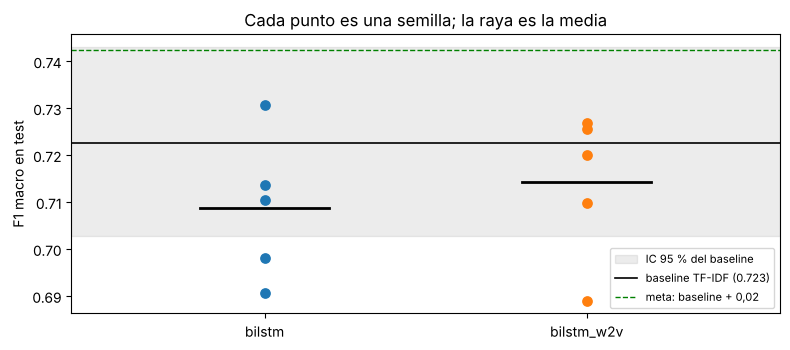

In [24]:
# 9.1 ¿La diferencia con el baseline es real o es azar? Semillas e intervalos de confianza por remuestreo (bootstrap pareado)
estab = pd.DataFrame({n: {'F1 test media (5 semillas)': np.mean([metricas(yte_i, PROBS[(n, s)]['test'])['f1_macro'] for s in SEMILLAS]),
                          'desv.': np.std([metricas(yte_i, PROBS[(n, s)]['test'])['f1_macro'] for s in SEMILLAS], ddof=1),
                          'mínimo': np.min([metricas(yte_i, PROBS[(n, s)]['test'])['f1_macro'] for s in SEMILLAS]),
                          'máximo': np.max([metricas(yte_i, PROBS[(n, s)]['test'])['f1_macro'] for s in SEMILLAS]),
                          'recall negativa media': np.mean([metricas(yte_i, PROBS[(n, s)]['test'])['recall_critico'] for s in SEMILLAS]),
                          'F1 externo media': np.mean([metricas(yext_i, PROBS[(n, s)]['externo'])['f1_macro'] for s in SEMILLAS])}
                      for n in VARIANTES}).T
f1_base = tablero.loc[BASE, 'F1 macro test']
estab['diferencia vs baseline'] = estab['F1 test media (5 semillas)'] - f1_base
display(estab.round(3))

rng = np.random.default_rng(SEED); n = len(yte_i); idx = [rng.integers(0, n, n) for _ in range(1000)]
pb = P[BASE]['test'].argmax(1); pa = P[AVANZADO]['test'].argmax(1)
f1_b = np.array([f1_score(yte_i[i], pb[i], average='macro') for i in idx]); f1_a = np.array([f1_score(yte_i[i], pa[i], average='macro') for i in idx])
dif = f1_a - f1_b
IC = {'baseline': np.percentile(f1_b, [2.5, 97.5]), AVANZADO: np.percentile(f1_a, [2.5, 97.5]), 'diferencia': np.percentile(dif, [2.5, 97.5])}
print(f'F1 macro test · baseline {f1_base:.3f} (IC 95 %: {IC["baseline"][0]:.3f} a {IC["baseline"][1]:.3f}) · '
      f'{AVANZADO} {tablero.loc[AVANZADO, "F1 macro test"]:.3f} (IC 95 %: {IC[AVANZADO][0]:.3f} a {IC[AVANZADO][1]:.3f})')
print(f'Diferencia {AVANZADO} − baseline: {dif.mean():+.3f} (IC 95 %: {IC["diferencia"][0]:+.3f} a {IC["diferencia"][1]:+.3f}) · '
      f'la red gana en el {np.mean(dif > 0):.0%} de los remuestreos y supera la meta de +0,02 en el {np.mean(dif >= CRITERIOS["mejora_f1_macro"]):.0%}')

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axhspan(*IC['baseline'], color='gray', alpha=.15, label='IC 95 % del baseline'); ax.axhline(f1_base, c='k', lw=1.2, label=f'baseline TF-IDF ({f1_base:.3f})')
ax.axhline(f1_base + CRITERIOS['mejora_f1_macro'], c='green', ls='--', lw=1, label='meta: baseline + 0,02')
for i, nombre in enumerate(VARIANTES):
    v = [metricas(yte_i, PROBS[(nombre, s)]['test'])['f1_macro'] for s in SEMILLAS]
    ax.scatter([i] * len(v), v, s=45, zorder=3); ax.plot([i - .2, i + .2], [np.mean(v)] * 2, c='k', lw=2)
ax.set_xticks(range(len(VARIANTES))); ax.set_xticklabels(list(VARIANTES)); ax.set_xlim(-.6, len(VARIANTES) - .4); ax.set_ylabel('F1 macro en test')
ax.set_title('Cada punto es una semilla; la raya es la media'); ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); guardar_figura('f1_semillas'); plt.show()

**¿La red es realmente mejor? No se puede afirmar.** Con 5 semillas, la media de la BiLSTM + Word2Vec en test es 0,714 (rango 0,689-0,727), por debajo del baseline (0,723). La semilla desplegada gana por +0,004, con un intervalo de confianza del 95 % de −0,015 a +0,023 que **incluye el cero**, y supera la meta de +0,02 solo en el 5 % de los remuestreos.
Elegir la mejor semilla en validación da una cifra optimista: pasa de 0,763 en validación a 0,727 en test.

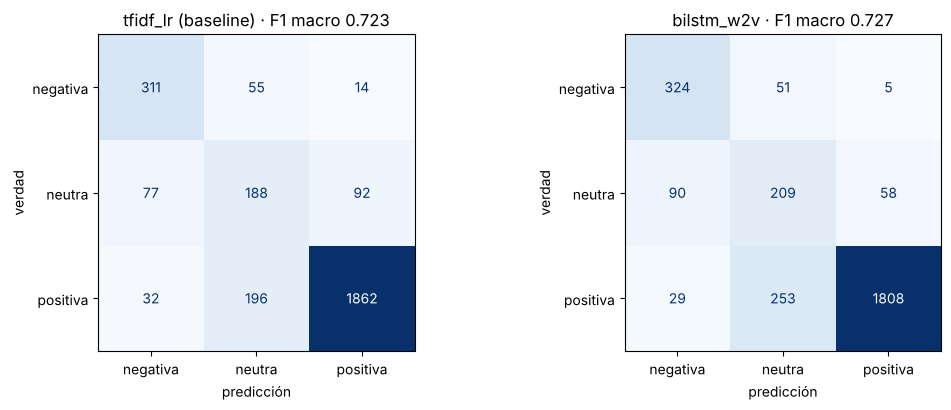

tfidf_lr (baseline)                       bilstm_w2v                      
                   precisión recall     F1 soporte  precisión recall     F1 soporte
negativa               0.740  0.818  0.778     380      0.731  0.853  0.787     380
neutra                 0.428  0.527  0.472     357      0.407  0.585  0.480     357
positiva               0.946  0.891  0.918    2090      0.966  0.865  0.913    2090

In [25]:
# 9.2 Desempeño por clase y matrices de confusión (filas = verdad, columnas = predicción)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, nombre in zip(ax, [BASE, AVANZADO]):
    ConfusionMatrixDisplay.from_predictions(yte_i, P[nombre]['test'].argmax(1), display_labels=CLASES, ax=a, colorbar=False, cmap='Blues')
    a.set_title(f'{nombre} · F1 macro {f1_score(yte_i, P[nombre]["test"].argmax(1), average="macro"):.3f}'); a.set_xlabel('predicción'); a.set_ylabel('verdad')
plt.tight_layout(); guardar_figura('matrices_confusion'); plt.show()
por_clase = {}
for nombre in [BASE, AVANZADO]:
    pred = P[nombre]['test'].argmax(1)
    por_clase[nombre] = pd.DataFrame({'precisión': precision_score(yte_i, pred, average=None), 'recall': recall_score(yte_i, pred, average=None),
                                      'F1': f1_score(yte_i, pred, average=None), 'soporte': np.bincount(yte_i)}, index=CLASES)
display(pd.concat(por_clase, axis=1).round(3))

La neutra es la clase difícil en los dos modelos (F1 0,47-0,48) y se confunde hacia los dos lados. La red recupera más negativas (recall 0,853 frente a 0,818), pero manda más positivas a neutra (253 frente a 196). La positiva casi no falla (F1 0,91-0,92).

## 10. Política de decisión: cuándo decide el modelo y cuándo una persona
El modelo no decide solo todos los casos. Tres reglas, con umbrales elegidos en **validación**:
1. **Alerta al coordinador** si P(negativa) ≥ τ, donde τ es el mayor valor que en validación alerta al menos el 90 % de las negativas.
2. **Revisión humana** si la confianza es menor que el umbral (el menor con el que lo automático acierta al menos el 90 % en validación) o si la predicción es neutra.
3. **Registro automático** en el resto.

La demo agrega dos controles de entrada antes del modelo: texto vacío, y texto en otro idioma o con más de 30 % de palabras desconocidas → revisión humana.

umbral      τ  recall negativa (solo argmax)  negativas con alerta  negativas que ve una persona (alerta o revisión)  negativas que se escapan (automáticas)  automáticas por 1.000  \
modelo              parte                                                                                                                                                                                             
tfidf_lr (baseline) validación    0.50  0.323                          0.850                 0.902                                             0.987                                   0.013                653.216   
                    test          0.50  0.323                          0.818                 0.879                                             0.995                                   0.005                645.561   
                    externo       0.50  0.323                          0.866                 0.924                                             0.998                                   0.002                437.186   
bilstm_w2v          validación    0.64  0.368                          0.880                 0.902                                             0.983                                   0.017                631.579   
                    test          0.64  0.368                          0.853                 0.874                                             0.992                                   0.008                618.677   
                    externo       0.64  0.368                          0.902                 0.918                                             0.996                                   0.004                433.836   

                                a revisión por 1.000  alertas por 1.000  acierto en las automáticas  
modelo              parte                                                                            
tfidf_lr (baseline) validación               164.912            181.871                       0.971  
                    test                     176.512            177.927                       0.964  
                    externo                  218.314            344.500                       0.959  
bilstm_w2v          validación               205.848            162.573                       0.981  
                    test                     212.947            168.376                       0.974  
                    externo                  234.506            331.658                       0.961

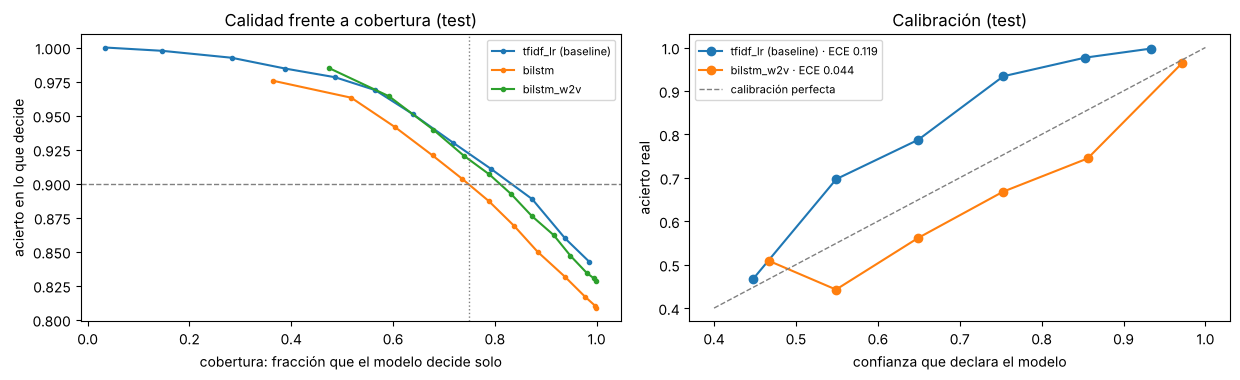

In [26]:
# 10. Política de decisión: umbral de abstención, regla de alerta para negativas y carga de revisión humana
def tau_negativa(y_val, prob_val, objetivo=CRITERIOS['recall_critico']):
    """τ elegido en VALIDACIÓN: el mayor valor que deja pasar al menos el 90 % de las negativas reales."""
    p = np.sort(prob_val[y_val == 0, 0]); return float(p[int(np.floor((1 - objetivo) * len(p)))])

def aplicar_politica(prob, umbral, tau, neutra_a_revision=True):
    """Decisión por reseña: 2 = alerta al coordinador, 1 = revisión humana, 0 = automática."""
    pred, conf = prob.argmax(1), prob.max(1)
    d = np.zeros(len(prob), int)
    d[(conf < umbral) | ((pred == 1) & neutra_a_revision)] = 1
    d[prob[:, 0] >= tau] = 2
    return d

POLITICAS, filas = {}, []
for nombre in [BASE, AVANZADO]:
    um, tau = tablero.loc[nombre, 'umbral (de val)'], tau_negativa(yval_i, P[nombre]['val'])
    POLITICAS[nombre] = dict(umbral_confianza=float(um), tau_negativa=round(float(tau), 3))
    for parte, y, prob in [('validación', yval_i, P[nombre]['val']), ('test', yte_i, P[nombre]['test']), ('externo', yext_i, P[nombre]['externo'])]:
        d = aplicar_politica(prob, um, tau)
        neg = y == 0
        filas.append({'modelo': nombre, 'parte': parte, 'umbral': um, 'τ': round(tau, 3),
                      'recall negativa (solo argmax)': (prob.argmax(1)[neg] == 0).mean(),
                      'negativas con alerta': (d[neg] == 2).mean(), 'negativas que ve una persona (alerta o revisión)': (d[neg] >= 1).mean(),
                      'negativas que se escapan (automáticas)': (d[neg] == 0).mean(),
                      'automáticas por 1.000': (d == 0).mean() * 1000, 'a revisión por 1.000': (d == 1).mean() * 1000, 'alertas por 1.000': (d == 2).mean() * 1000,
                      'acierto en las automáticas': (prob.argmax(1)[d == 0] == y[d == 0]).mean()})
politica_tabla = pd.DataFrame(filas).set_index(['modelo', 'parte'])
display(politica_tabla.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
for nombre in [BASE] + list(VARIANTES):
    prob = P[nombre]['test']; conf, ok = prob.max(1), prob.argmax(1) == yte_i
    qc = [(np.mean(conf >= th), ok[conf >= th].mean()) for th in np.arange(.4, .96, .05)]
    ax[0].plot(*zip(*qc), marker='o', ms=3, label=nombre)
ax[0].axhline(CALIDAD_AUTO, ls='--', c='gray', lw=1); ax[0].axvline(1 - CRITERIOS['abstencion_max'], ls=':', c='gray', lw=1)
ax[0].set_xlabel('cobertura: fracción que el modelo decide solo'); ax[0].set_ylabel('acierto en lo que decide'); ax[0].set_title('Calidad frente a cobertura (test)'); ax[0].legend(fontsize=8)
for nombre in [BASE, AVANZADO]:
    prob = P[nombre]['test']; g = pd.DataFrame({'conf': prob.max(1), 'ok': prob.argmax(1) == yte_i, 'tramo': pd.cut(prob.max(1), [0, .5, .6, .7, .8, .9, 1])}).groupby('tramo', observed=True).agg(c=('conf', 'mean'), a=('ok', 'mean'))
    ax[1].plot(g.c, g.a, marker='o', label=f'{nombre} · ECE {ece(yte_i, prob):.3f}')
ax[1].plot([.4, 1], [.4, 1], ls='--', c='gray', lw=1, label='calibración perfecta')
ax[1].set_xlabel('confianza que declara el modelo'); ax[1].set_ylabel('acierto real'); ax[1].set_title('Calibración (test)'); ax[1].legend(fontsize=8)
plt.tight_layout(); guardar_figura('abstencion_calibracion'); plt.show()

**Qué pasa con 1.000 reseñas de sedes nuevas (test, baseline):** 646 se registran solas (y aciertan el 96 %), 177 van a revisión y 178 generan alerta.
- Las alertas capturan el **87,9 % de las negativas**, menos que el 90,2 % de validación: la meta prerregistrada (≥ 0,90) **no se cumple en test**. El umbral elegido en validación pierde algo al pasar a sedes nuevas.
- Pero entre alerta y revisión, **una persona ve el 99,5 % de las negativas**; solo el 0,5 % se registra sin que nadie la lea.
- En la prueba externa, con más quejas, las alertas suben a 345 por 1.000: la carga de los coordinadores depende de la mezcla de reseñas, no solo del modelo.
- En el gráfico de calibración el baseline queda por encima de la diagonal (acierta más de lo que declara) y la red queda casi sobre ella.

## 11. Desempeño por segmento
Un buen promedio puede esconder un grupo mal atendido. Se mira por provincia (en Bodytech: la ciudad) y por longitud de la reseña.

In [27]:
# 11. Desempeño por segmento: provincia (ciudad), longitud y fuente. Un buen promedio puede esconder un grupo mal atendido.
filas = {}
for p in test.provincia.value_counts().index:
    m = (test.provincia == p).values
    if m.sum() < 50: continue                                                   # con menos de 50 reseñas la cifra no es confiable
    fila = {'reseñas': int(m.sum()), 'negativas': int((yte_i[m] == 0).sum())}
    for nombre in [BASE, AVANZADO]:
        pred = P[nombre]['test'].argmax(1)[m]
        fila[f'F1 macro · {nombre}'] = f1_score(yte_i[m], pred, average='macro')
        fila[f'recall negativa · {nombre}'] = recall_score(yte_i[m], pred, labels=[0], average=None, zero_division=np.nan)[0]
    filas[p] = fila
por_provincia = pd.DataFrame(filas).T
display(por_provincia.round(3))
tramos = pd.cut(test.n_tokens, [0, 60, 100, 160, 10000], labels=['hasta 60', '61-100', '101-160', 'más de 160'])
display(pd.DataFrame({nombre: pd.Series(P[nombre]['test'].argmax(1) == yte_i).groupby(tramos.values, observed=False).mean() for nombre in [BASE, AVANZADO]})
        .assign(reseñas=tramos.value_counts()).rename_axis('tokens').round(3).rename(columns={BASE: f'acierto · {BASE}', AVANZADO: f'acierto · {AVANZADO}'}))

,reseñas,negativas,F1 macro · tfidf_lr (baseline),recall negativa · tfidf_lr (baseline),F1 macro · bilstm_w2v,recall negativa · bilstm_w2v
Sevilla,853.0,131.0,0.740,0.824,0.748,0.855
Granada,562.0,76.0,0.730,0.776,0.733,0.868
Málaga,474.0,48.0,0.755,0.833,0.722,0.833
Córdoba,393.0,28.0,0.663,0.857,0.705,0.821
Almería,304.0,54.0,0.682,0.852,0.709,0.870
Huelva,137.0,26.0,0.725,0.769,0.725,0.923
Jaén,104.0,17.0,0.661,0.824,0.626,0.706


,acierto · tfidf_lr (baseline),acierto · bilstm_w2v,reseñas
tokens,,,
hasta 60,0.893,0.874,1416
61-100,0.805,0.806,775
101-160,0.740,0.751,615
más de 160,0.810,0.810,21


- **Por provincia**, el F1 del baseline va de 0,661 (Jaén) a 0,755 (Málaga), y su recall de negativas de 0,769 (Huelva) a 0,857 (Córdoba). Con pocas negativas por provincia (17 en Jaén, 26 en Huelva) estas cifras son inestables: en un despliegue hay que vigilar aparte las ciudades con menos datos.
- **Por longitud**, las reseñas cortas son las más fáciles (89 % de acierto hasta 60 tokens) y las de 101 a 160 tokens las más difíciles (74 %): las reseñas largas mezclan elogios y quejas.

## 12. Análisis de errores
Se buscan patrones: qué rasgos aparecen más en los errores que en los aciertos, qué confusiones dominan y una causa probable para cada error, con ejemplos para leer uno por uno.

In [28]:
# 12. Análisis de errores en test: factores, tipos de confusión y causa probable de cada error
CONTRASTE = r'\b(?:pero|aunque|sin embargo|eso sí|lo único|a pesar|no obstante|por lo demás|en cambio|salvo|excepto)\b'
NEGACION = {'no', 'ni', 'nunca', 'nada', 'tampoco', 'sin', 'jamás', 'ningún', 'ninguna', 'ninguno'}
an = test[['texto', 'sentimiento', 'rating', 'n_tokens', 'cortada']].copy()
an['calificación fronteriza (2★-4★)'] = an.rating.isin([2, 3, 4])
an['contraste (pero, aunque…)'] = test.texto.str.lower().str.contains(CONTRASTE)
an['3 o más negaciones'] = test.seq.map(lambda s: sum(w in NEGACION for w in s.split()) >= 3)
an['cortada en el origen'] = test.cortada
an['truncada (> 160 tokens)'] = an.n_tokens > SEQ_LEN
an['OOV ≥ 6 %'] = ((Xte_s == 1).sum(1) / np.maximum((Xte_s != 0).sum(1), 1)) >= .06
FACTORES = ['calificación fronteriza (2★-4★)', 'contraste (pero, aunque…)', '3 o más negaciones', 'cortada en el origen', 'truncada (> 160 tokens)', 'OOV ≥ 6 %']
for nombre in [BASE, AVANZADO]:
    an[f'pred {nombre}'] = le.classes_[P[nombre]['test'].argmax(1)]; an[f'conf {nombre}'] = P[nombre]['test'].max(1)
    an[f'error {nombre}'] = an[f'pred {nombre}'] != an.sentimiento
comp = {}
for nombre in [BASE, AVANZADO]:
    e = an[f'error {nombre}']
    comp[nombre] = pd.DataFrame({'% en errores': an[e][FACTORES].mean() * 100, '% en aciertos': an[~e][FACTORES].mean() * 100})
    comp[nombre]['veces más frecuente en errores'] = comp[nombre]['% en errores'] / comp[nombre]['% en aciertos']
print('Errores en test →', {n: int(an[f'error {n}'].sum()) for n in [BASE, AVANZADO]}, 'de', len(an),
      '| errores comunes a los dos modelos:', int((an[f'error {BASE}'] & an[f'error {AVANZADO}']).sum()))
display(pd.concat(comp, axis=1).round(1))
print('Tipo de confusión (verdad → predicción):')
display(pd.DataFrame({n: (an[an[f'error {n}']].sentimiento + ' → ' + an[an[f'error {n}']][f'pred {n}']).value_counts() for n in [BASE, AVANZADO]}).fillna(0).astype(int))
print('% de reseñas mal clasificadas según sus estrellas:')
display(pd.DataFrame({n: an.groupby('rating')[f'error {n}'].mean().mul(100).round(1) for n in [BASE, AVANZADO]}).T)
fronterizos = {n: an[an[f'error {n}']]['calificación fronteriza (2★-4★)'].mean() for n in [BASE, AVANZADO]}
print('Errores en reseñas de 2★ a 4★:', {n: f'{v:.0%}' for n, v in fronterizos.items()})

def causa_probable(r):
    if r['calificación fronteriza (2★-4★)'] and r['contraste (pero, aunque…)']: return 'A. Opinión mixta en una reseña de 2★-4★'
    if r['calificación fronteriza (2★-4★)']: return 'B. Reseña de 2★-4★ sin contraste explícito'
    if r['contraste (pero, aunque…)']: return 'C. Contraste en una reseña de 1★ o 5★'
    if r['3 o más negaciones']: return 'D. Negación en una reseña de 1★ o 5★'
    if r['cortada en el origen'] or r['truncada (> 160 tokens)']: return 'E. Falta el final de la reseña'
    if r['OOV ≥ 6 %']: return 'F. Muchas palabras desconocidas'
    return 'G. Otra causa'
an['causa probable'] = an.apply(causa_probable, axis=1)
display(pd.DataFrame({n: an[an[f'error {n}']]['causa probable'].value_counts() for n in [BASE, AVANZADO]}).fillna(0).astype(int).sort_index())

Errores en test → {'tfidf_lr (baseline)': 466, 'bilstm_w2v': 486} de 2827 | errores comunes a los dos modelos: 332


tfidf_lr (baseline)                                                bilstm_w2v                                             
                                       % en errores % en aciertos veces más frecuente en errores % en errores % en aciertos veces más frecuente en errores
calificación fronteriza (2★-4★)                84.1          35.3                            2.4         81.9          35.4                            2.3
contraste (pero, aunque…)                      74.9          39.1                            1.9         73.0          39.2                            1.9
3 o más negaciones                             34.3          17.4                            2.0         32.7          17.6                            1.9
cortada en el origen                           21.2           9.1                            2.3         19.1           9.5                            2.0
truncada (> 160 tokens)                         0.9           0.7                            1.2          0.8           0.7                            1.1
OOV ≥ 6 %                                      13.3          11.9                            1.1         13.4          11.8                            1.1

Tipo de confusión (verdad → predicción):


,tfidf_lr (baseline),bilstm_w2v
negativa → neutra,55,51
negativa → positiva,14,5
neutra → negativa,77,90
neutra → positiva,92,58
positiva → negativa,32,29
positiva → neutra,196,253


% de reseñas mal clasificadas según sus estrellas:


rating,1,2,3,4,5
tfidf_lr (baseline),4.7,39.5,47.3,22.9,4.6
bilstm_w2v,5.6,29.3,41.5,28.7,5.5


Errores en reseñas de 2★ a 4★: {'tfidf_lr (baseline)': '84%', 'bilstm_w2v': '82%'}


,tfidf_lr (baseline),bilstm_w2v
causa probable,,
A. Opinión mixta en una reseña de 2★-4★,288,292
B. Reseña de 2★-4★ sin contraste explícito,104,106
C. Contraste en una reseña de 1★ o 5★,61,63
D. Negación en una reseña de 1★ o 5★,3,5
E. Falta el final de la reseña,2,4
F. Muchas palabras desconocidas,2,1
G. Otra causa,6,15


- **466 errores del baseline y 486 de la red en 2.827 reseñas; 332 son comunes.** Los dos modelos fallan en los mismos casos, lo que apunta a los datos más que al modelo.
- El rasgo más ligado al error es la **calificación fronteriza**: el 84 % de los errores son reseñas de 2★ a 4★ (frente al 35 % de los aciertos). Le siguen las reseñas **cortadas en origen** (2,3 veces más frecuentes en los errores), las **negaciones múltiples** (2,0) y el **contraste** con «pero» o «aunque» (1,9).
- La confusión más común es **positiva → neutra** (196 y 253 casos). El error más caro, **negativa → positiva**, es raro (14 y 5).
- Por causa probable, **el 62 % de los errores del baseline (288 de 466) son opiniones mixtas en reseñas de 2★ a 4★**: el texto trae elogios y quejas y la etiqueta depende de cuántas estrellas puso el autor.

In [29]:
# 12.1 Errores representativos para leer uno por uno: de cada causa, los 2 en los que cada modelo estaba más seguro
pd.set_option('display.max_colwidth', 260)
for nombre, otro in [(BASE, AVANZADO), (AVANZADO, BASE)]:
    err = an[an[f'error {nombre}']].sort_values(f'conf {nombre}', ascending=False).groupby('causa probable').head(2).sort_values('causa probable')
    err = err.assign(texto_corto=err.texto.map(lambda s: s if len(s) < 240 else s[:160] + ' […] ' + s[-70:]))
    vista = err[['causa probable', 'sentimiento', 'rating', f'pred {nombre}', f'conf {nombre}', f'pred {otro}', 'texto_corto']].rename(columns={
        'sentimiento': 'verdad', 'rating': '★', f'pred {nombre}': 'predijo', f'conf {nombre}': 'confianza', f'pred {otro}': f'el otro modelo ({otro})', 'texto_corto': 'texto'})
    print(f'\n{len(vista)} errores de {nombre}:'); display(vista.round(2).reset_index(drop=True))
    vista.to_csv(config.DIR_RESULTADOS / f'errores_{nombre.split()[0]}.csv', index=False)
pd.set_option('display.max_colwidth', 150)


14 errores de tfidf_lr (baseline):


,causa probable,verdad,★,predijo,confianza,el otro modelo (bilstm_w2v),texto
0,A. Opinión mixta en una reseña de 2★-4★,neutra,3,positiva,0.91,positiva,"Buena estadía. El Hotel está muy bien ubicado, en pleno casco antiguo, pero muy tranquilo. El personal super amables; muy bien ambientado, resulta muy agradable […] alle del un rincón con libros en el hall de entrada me pareció genial,"
1,A. Opinión mixta en una reseña de 2★-4★,neutra,3,negativa,0.90,negativa,"Mala limpieza. Habían varios pelos en la almohada, lo que significa que estaban sin lavar fundas y sábanas, por lo que dormimos sin usar las almohadas ni taparn […] por económico al ser apartamento con piscina, pero no sé si compensa."
2,B. Reseña de 2★-4★ sin contraste explícito,neutra,3,negativa,0.85,negativa,Le faltan cosas.... Creo que poder describir fielmente las instalaciones le ayudaría mucho. Me sorprende que no existiera en la habitación ni mini bar ni una bo […] la aplicación tampoco da opción clara para solicitar dicho servicio..
3,B. Reseña de 2★-4★ sin contraste explícito,neutra,3,positiva,0.84,positiva,Ambiente familiar. Trato excelente por parte de todo el personal. Habitaciones sencillas. Aparcamiento en los alrededores. En la cafetería se echa de menos comida al momento ( todo lo tienen precocinado) Buen desayuno..
4,C. Contraste en una reseña de 1★ o 5★,negativa,1,neutra,0.79,neutra,"[NOMBRE] lejos!. El personal es amable, serviciales, y eso es todo en contra. Muy, muy sucio sitio. Todo necesita reformas, comienza con baño y terminando en cocina. Si sólo necesita cama, está bien, pero no para algo más"
5,C. Contraste en una reseña de 1★ o 5★,positiva,5,neutra,0.75,neutra,"Buena y barata. La verdad es que la pensión es exactamente lo que buscábamos, la habitación era de 3 personas pero nos dejó el precio para dos. La habitación te […] es que estar en el centro, con ese precio y esa calidad, es perfecto."
6,D. Negación en una reseña de 1★ o 5★,positiva,5,neutra,0.44,neutra,"Excelente alojamiento. Este hostal en el centro de Huelva es una joya en lo que a mí respecta. Relación calidad-precio es excepcional, no estoy seguro de lo que […] rsona o dos amigos. Una pareja sin necesidad de estar muy cerca en una"
7,D. Negación en una reseña de 1★ o 5★,negativa,1,positiva,0.41,neutra,No traer a su perro!. No se permiten mascotas en absoluto! Tienes que amarrar su perro para el árbol fuera del restaurante. Tienen 11 años y un perro agresivo q […] espaciosa habitación con gran acceso a internet wi-fi. (3 habitación)
8,E. Falta el final de la reseña,positiva,5,negativa,0.58,negativa,"Día con encanto 😍. Nos parece un lugar encantador , al que vamos cada año con los abuelos y los niños, solo para ver el paisaje, pasear un rato y acabar comiend […] cárselo 😏. Tanto los camareros como la gente de la barra de categoría."
9,E. Falta el final de la reseña,positiva,5,negativa,0.44,negativa,Volvería a alojarme. La recepcionista fue muy amable nos explico cada una de las llaves y nos acompañó hasta la puerta de la habitación. Íbamos 3 amigas y elegi […] as y cubiertos que hubieras utilizado el horario del desayuno era de 9



13 errores de bilstm_w2v:


,causa probable,verdad,★,predijo,confianza,el otro modelo (tfidf_lr (baseline)),texto
0,A. Opinión mixta en una reseña de 2★-4★,neutra,3,positiva,0.99,positiva,"Opinión. La recepcionistas han sido muy agradables con nosotros, pero especialmente [NOMBRE] ha solucionado un pequeño inconveniente que nos ha surgido en el ho […] uy agradable encontrarse personas que sean tan profesionales, gracias."
1,A. Opinión mixta en una reseña de 2★-4★,neutra,3,negativa,0.99,negativa,Han bajado la calidad del servicio. Después de ir anteriormente 4 veces no sé porque motivo será pero en concreto este hotel de la cadena NH ha bajado mucho los […] mi opinión antes era caro pero se lo merecía ahora ya no se lo merece.
2,B. Reseña de 2★-4★ sin contraste explícito,neutra,3,positiva,0.97,positiva,Ambiente familiar. Trato excelente por parte de todo el personal. Habitaciones sencillas. Aparcamiento en los alrededores. En la cafetería se echa de menos comida al momento ( todo lo tienen precocinado) Buen desayuno..
3,B. Reseña de 2★-4★ sin contraste explícito,neutra,3,negativa,0.96,negativa,"No comáis en la piscina. La habitación, la piscina y el personal muy bien, el bar de la piscina pésimo, todo excesivamente escaso y muy caro, no suelo quejarme […] zos de pimientos 4 trocitos de cebolla y 4 de champiñón, vamos un robo"
4,C. Contraste en una reseña de 1★ o 5★,positiva,5,neutra,0.92,neutra,"Ubicación perfecta, reforma a medias. La ubicación del hotel es perfecta. El resto del hotel da la sensación que la reforma se ha quedado a medias. Tiene luces […] cho, pero algo pasado de precio para lo que es. Bien pero no excelente"
5,C. Contraste en una reseña de 1★ o 5★,positiva,5,negativa,0.90,negativa,"Habitación 304. Cercano al centro, nada ruidoso, con la mejor cafetería churrería debajo del hotel de toda Sevilla. El pk horrible, y deben hacer algo, el clien […] trato ejemplar, habítacion reformada. Todo de notable. Lo mata el PK."
6,D. Negación en una reseña de 1★ o 5★,positiva,5,neutra,0.90,negativa,"Bien situado, económico y la dueña un 10. Encontré este hostal por recomendación y después de visitarlo quiero re-recomendarlo. Lo regenta una mujer Alemana sim […] son muy económicos y las habitaciones tienen un encanto muy especial."
7,D. Negación en una reseña de 1★ o 5★,positiva,5,neutra,0.68,positiva,"Económico y muy bien ubicado. Tercera vez aquí, y aún contenta con el servicio. Esta vez me encontré con una amiga Ana quien no habla mucho español, y pudo regi […] pudimos salir en las noches sin problema ya que todo queda muy cerca."
8,E. Falta el final de la reseña,positiva,5,negativa,0.94,negativa,Volvería a alojarme. La recepcionista fue muy amable nos explico cada una de las llaves y nos acompañó hasta la puerta de la habitación. Íbamos 3 amigas y elegi […] as y cubiertos que hubieras utilizado el horario del desayuno era de 9
9,E. Falta el final de la reseña,positiva,5,negativa,0.65,positiva,"Trato muy distinto, internet sin pagar.. Hotel que se descata por el servicio básico y de muy buen nivel. Hemos apreciado en particular la habitación enorme en […] servizio di internet gratuito con la possibilità di stampare documenti"


Leídos uno por uno, muchos «errores» son discutibles. Una reseña de 3★ titulada «Han bajado la calidad del servicio», que termina «ahora ya no se lo merece», se predice **negativa** con 0,99 de confianza: para un coordinador, eso es una queja que conviene atender. Otra de 3★ («Trato excelente… Buen desayuno») se predice positiva. Esto confirma que el límite principal es la etiqueta por estrellas y no solo el modelo: con datos de Bodytech, el primer paso sería etiquetar a mano una muestra.

## 13. Robustez
Tres pruebas: (1) **casos escritos a mano** que cambian una sola cosa (contrafactuales), incluidos textos con vocabulario de gimnasio; (2) **perturbaciones de todo el test** (mayúsculas, sin tildes, errores de tecleo, sin título, solo la primera mitad); (3) **entradas fuera de alcance** (otro idioma, otro tema, texto degenerado).

In [30]:
# 13. Robustez: contrafactuales escritos a mano, perturbaciones de todo el test, otros idiomas y texto fuera de dominio
def probabilidades(textos, nombre):
    limpios = [normalizar(t) for t in textos]
    return base.predict_proba(limpios) if nombre == BASE else MEJOR[nombre][2].predict(tv(tf.constant([a_secuencia(t) for t in limpios])), verbose=0, batch_size=256)

casos = pd.DataFrame([
    ('afirmación', 'Sede recomendable. Las máquinas estaban limpias, el personal fue amable y las clases muy buenas. Volveré.', 'positiva'),
    ('negación', 'Sede nada recomendable. Las máquinas no estaban limpias, el personal no fue amable y las clases no eran buenas. No volveré.', 'negativa'),
    ('orden A (mismas palabras)', 'No es malo, es bueno', 'positiva'),
    ('orden B (mismas palabras)', 'No es bueno, es malo', 'negativa'),
    ('contraste', 'Buena ubicación. La ubicación es buena, pero las duchas estaban sucias y había mucho ruido. No la recomiendo.', 'negativa'),
    ('errores de escritura', 'Sede nada recomendavle. Las duchas no estavan linpias y el personal no fue amavle.', 'negativa'),
    ('mayúsculas y signos', 'PÉSIMO SERVICIO!!! NUNCA HAY AGUA CALIENTE Y NADIE RESPONDE. NO VUELVO!!!', 'negativa'),
    ('ironía', 'Genial, solo tardaron dos horas en atenderme. Maravilloso.', 'negativa'),
    ('vocabulario de gimnasio', 'Las máquinas de cardio siempre están dañadas y nunca hay cupo en spinning. Pienso cancelar el plan.', 'negativa'),
    ('emoji', 'Todo perfecto 😍😍', 'positiva'),
    ('una palabra repetida', 'bien ' * 300, 'fuera de alcance'),
    ('otro idioma', 'Terrible gym. The showers were dirty and the staff was rude. We will not come back.', 'fuera de alcance'),
    ('fuera de dominio', 'La fotosíntesis depende de la luz', 'fuera de alcance'),
], columns=['caso', 'texto', 'esperado'])
for nombre in [BASE, AVANZADO]:
    prob = probabilidades(casos.texto.tolist(), nombre)
    casos[nombre] = [f'{le.classes_[i]} ({p:.2f})' for i, p in zip(prob.argmax(1), prob.max(1))]
casos['palabras desconocidas (baseline)'] = [f'{palabras_desconocidas(base, normalizar(t)):.0%}' for t in casos.texto]
casos['texto'] = casos.texto.str.slice(0, 90)
display(casos)

def con_errores(s, prob, rng):
    salida = []
    for w in s.split():
        if len(w) >= 5 and rng.random() < prob:
            i = int(rng.integers(1, len(w) - 2)); w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
        salida.append(w)
    return ' '.join(salida)
rng = np.random.default_rng(SEED)
variantes = {'original': test.texto, 'todo en MAYÚSCULAS': test.texto.str.upper(), 'sin tildes': test.texto.map(sin_tildes),
             'errores de tecleo en 1 de cada 10 palabras': test.texto.map(lambda s: con_errores(s, .10, rng)),
             'errores de tecleo en 3 de cada 10 palabras': test.texto.map(lambda s: con_errores(s, .30, rng)),
             'sin título': test.resena, 'solo la primera mitad': test.texto.map(lambda s: ' '.join(s.split()[:max(len(s.split()) // 2, 1)]))}
filas = {}
for nv, textos in variantes.items():
    fila = {}
    for nombre in [BASE, AVANZADO]:
        pred = probabilidades(textos.tolist(), nombre).argmax(1)
        fila[f'F1 · {nombre}'] = f1_score(yte_i, pred, average='macro'); fila[f'recall negativa · {nombre}'] = recall_score(yte_i, pred, labels=[0], average=None)[0]
    filas[nv] = fila
rob = pd.DataFrame(filas).T
for nombre in [BASE, AVANZADO]: rob[f'cambio F1 · {nombre}'] = rob[f'F1 · {nombre}'] - rob.loc['original', f'F1 · {nombre}']
display(rob.round(3))

otros = otros_idiomas.texto.tolist()
oov_otros = np.array([palabras_desconocidas(base, t) for t in otros]); oov_test = np.array([palabras_desconocidas(base, t) for t in test.texto])
filas = {}
for nombre in [BASE, AVANZADO]:
    prob = probabilidades(otros, nombre); um = tablero.loc[nombre, 'umbral (de val)']
    filas[nombre] = {'reseñas en otro idioma': len(otros), 'acierto': (le.classes_[prob.argmax(1)] == otros_idiomas.sentimiento.values).mean(),
                     'confianza media': prob.max(1).mean(), '% que supera el umbral y se decidiría solo': (prob.max(1) >= um).mean() * 100}
display(pd.DataFrame(filas).T.round(3))
print(f'Palabras desconocidas para el baseline (media): otros idiomas {oov_otros.mean():.0%} | test en español {oov_test.mean():.1%}')
print(f'Regla «más del 30 % de palabras desconocidas → revisión humana»: detiene el {np.mean(oov_otros > .30):.0%} de las reseñas en otro idioma '
      f'y el {np.mean(oov_test > .30):.2%} de las reseñas en español del test')

,caso,texto,esperado,tfidf_lr (baseline),bilstm_w2v,palabras desconocidas (baseline)
0,afirmación,"Sede recomendable. Las máquinas estaban limpias, el personal fue amable y las clases muy b",positiva,positiva (0.81),positiva (0.98),0%
1,negación,"Sede nada recomendable. Las máquinas no estaban limpias, el personal no fue amable y las c",negativa,negativa (0.46),negativa (0.51),0%
2,orden A (mismas palabras),"No es malo, es bueno",positiva,neutra (0.44),neutra (0.64),0%
3,orden B (mismas palabras),"No es bueno, es malo",negativa,negativa (0.45),neutra (0.66),0%
4,contraste,"Buena ubicación. La ubicación es buena, pero las duchas estaban sucias y había mucho ruido",negativa,negativa (0.56),neutra (0.69),0%
5,errores de escritura,Sede nada recomendavle. Las duchas no estavan linpias y el personal no fue amavle.,negativa,negativa (0.53),negativa (0.89),31%
6,mayúsculas y signos,PÉSIMO SERVICIO!!! NUNCA HAY AGUA CALIENTE Y NADIE RESPONDE. NO VUELVO!!!,negativa,negativa (0.86),negativa (1.00),0%
7,ironía,"Genial, solo tardaron dos horas en atenderme. Maravilloso.",negativa,positiva (0.55),positiva (0.69),0%
8,vocabulario de gimnasio,Las máquinas de cardio siempre están dañadas y nunca hay cupo en spinning. Pienso cancelar,negativa,negativa (0.44),negativa (0.72),25%
9,emoji,Todo perfecto 😍😍,positiva,positiva (0.96),positiva (0.96),0%


,F1 · tfidf_lr (baseline),recall negativa · tfidf_lr (baseline),F1 · bilstm_w2v,recall negativa · bilstm_w2v,cambio F1 · tfidf_lr (baseline),cambio F1 · bilstm_w2v
original,0.723,0.818,0.727,0.853,0.000,0.000
todo en MAYÚSCULAS,0.723,0.818,0.727,0.853,0.000,0.000
sin tildes,0.711,0.826,0.732,0.855,-0.012,0.005
errores de tecleo en 1 de cada 10 palabras,0.713,0.821,0.697,0.879,-0.009,-0.030
errores de tecleo en 3 de cada 10 palabras,0.698,0.847,0.578,0.937,-0.025,-0.149
sin título,0.701,0.811,0.678,0.842,-0.021,-0.048
solo la primera mitad,0.683,0.768,0.681,0.779,-0.039,-0.046


,reseñas en otro idioma,acierto,confianza media,% que supera el umbral y se decidiría solo
tfidf_lr (baseline),130.0,0.792,0.621,82.308
bilstm_w2v,130.0,0.192,0.915,94.615


Palabras desconocidas para el baseline (media): otros idiomas 64% | test en español 3.0%
Regla «más del 30 % de palabras desconocidas → revisión humana»: detiene el 99% de las reseñas en otro idioma y el 0.04% de las reseñas en español del test


- **Negación:** los dos modelos entienden la negación simple («nada recomendable», «no estaban limpias»), pero con poca confianza (0,46 y 0,51). Con **las mismas palabras en otro orden** («No es malo, es bueno» / «No es bueno, es malo») ninguno acierta los dos casos: es el límite de mirar palabras sueltas.
- **Ironía:** los dos fallan («Genial, solo tardaron dos horas en atenderme. Maravilloso.» → positiva).
- **Vocabulario de gimnasio:** «Las máquinas de cardio siempre están dañadas y nunca hay cupo en spinning…» se clasifica bien como negativa, aunque el 25 % de sus palabras no existe en las reseñas de hoteles.
- **Perturbaciones:** las mayúsculas no afectan; sin tildes o con errores leves el baseline pierde alrededor de 0,01. Con errores de tecleo en 3 de cada 10 palabras **la red se hunde (−0,149) y el baseline aguanta (−0,025)**. Quedarse con la primera mitad de la reseña cuesta unos 0,04 a los dos.
- **Otro idioma:** los modelos asignan confianza alta a textos que no entienden (la red: 0,92 de confianza media con 19 % de acierto). **La confianza no sirve como alarma.** La regla de «más del 30 % de palabras desconocidas» detiene el 99 % de las reseñas en otro idioma y solo el 0,04 % de las reseñas en español.
- **Fuera de alcance:** «La fotosíntesis depende de la luz» se clasifica como negativa y generaría una alerta falsa; «bien» repetido 300 veces sale neutra con 0,99 de confianza en la red. Ningún control actual detecta un texto fuera de tema: queda en la matriz de riesgos.

## 14. Monitoreo y *drift*
En producción las etiquetas no llegan a tiempo: hay que vigilar señales que no las necesitan. Se simula un «lote nuevo» con la fuente B (otra época y otro recolector) y se compara con el test. El **PSI** (índice de estabilidad de la población) mide cuánto cambió una distribución: menos de 0,1 es estable, más de 0,25 es un cambio fuerte.

In [31]:
# 14. Monitoreo y drift: la fuente B (otra época y otro recolector) se trata como un "lote nuevo" frente al test de referencia
def psi(referencia, actual, bins=10):
    """Índice de estabilidad de la población: < 0,1 estable · 0,1-0,25 cambio moderado · > 0,25 cambio fuerte."""
    cortes = np.unique(np.quantile(referencia, np.linspace(0, 1, bins + 1))); cortes[0], cortes[-1] = -np.inf, np.inf
    r = np.histogram(referencia, cortes)[0] / len(referencia); a = np.histogram(actual, cortes)[0] / len(actual)
    r, a = np.clip(r, 1e-4, None), np.clip(a, 1e-4, None)
    return float(np.sum((a - r) * np.log(a / r)))

def indicadores(tabla, prob, umbral, tau):
    d = aplicar_politica(prob, umbral, tau); pred = prob.argmax(1)
    return {'reseñas': len(tabla), 'tokens (mediana)': float(tabla.n_tokens.median()),
            '% palabras desconocidas (media)': float(np.mean([palabras_desconocidas(base, t) for t in tabla.texto]) * 100),
            '% predichas negativas': float((pred == 0).mean() * 100), '% predichas neutras': float((pred == 1).mean() * 100),
            'confianza media': float(prob.max(1).mean()), '% a revisión o alerta': float((d >= 1).mean() * 100)}
pol = POLITICAS[BASE]
ref = indicadores(test, P[BASE]['test'], pol['umbral_confianza'], pol['tau_negativa'])
nuevo = indicadores(externo, P[BASE]['externo'], pol['umbral_confianza'], pol['tau_negativa'])
monitoreo = pd.DataFrame({'referencia (test)': ref, 'lote nuevo (fuente B)': nuevo})
monitoreo['cambio'] = monitoreo['lote nuevo (fuente B)'] - monitoreo['referencia (test)']
display(monitoreo.round(2))
PSI = {'longitud (tokens)': psi(test.n_tokens, externo.n_tokens), 'confianza del modelo': psi(P[BASE]['test'].max(1), P[BASE]['externo'].max(1)),
       'P(negativa)': psi(P[BASE]['test'][:, 0], P[BASE]['externo'][:, 0])}
print('PSI frente a la referencia:', {k: round(v, 3) for k, v in PSI.items()})
DISPARADORES = [('PSI de longitud > 0,25', PSI['longitud (tokens)'] > .25), ('PSI de confianza > 0,25', PSI['confianza del modelo'] > .25),
                ('palabras desconocidas > 10 %', nuevo['% palabras desconocidas (media)'] > 10),
                ('% predichas negativas cambia más de 5 puntos', abs(nuevo['% predichas negativas'] - ref['% predichas negativas']) > 5),
                ('revisión o alerta > 45 %', nuevo['% a revisión o alerta'] > 45)]
display(pd.DataFrame(DISPARADORES, columns=['disparador', '¿se activa?']).replace({True: 'SÍ', False: 'no'}))
print(f"F1 macro real del lote nuevo (se conoce solo con una muestra etiquetada): {tablero.loc[BASE, 'F1 macro externo']:.3f} frente a {f1_base:.3f} en la referencia")

,referencia (test),lote nuevo (fuente B),cambio
reseñas,2827.00,1791.00,-1036.00
tokens (mediana),60.00,105.00,45.00
% palabras desconocidas (media),3.01,4.52,1.52
% predichas negativas,14.86,29.98,15.13
% predichas neutras,15.53,20.83,5.30
confianza media,0.72,0.68,-0.04
% a revisión o alerta,35.44,56.28,20.84


PSI frente a la referencia: {'longitud (tokens)': 0.624, 'confianza del modelo': 0.065, 'P(negativa)': 0.27}


,disparador,¿se activa?
0,"PSI de longitud > 0,25",SÍ
1,"PSI de confianza > 0,25",no
2,palabras desconocidas > 10 %,no
3,% predichas negativas cambia más de 5 puntos,SÍ
4,revisión o alerta > 45 %,SÍ


F1 macro real del lote nuevo (se conoce solo con una muestra etiquetada): 0.744 frente a 0.723 en la referencia


- Las señales se mueven como se esperaba: reseñas casi el doble de largas (PSI de longitud 0,62, cambio fuerte), el doble de negativas predichas (30 % frente a 15 %) y más carga humana (56 % a revisión o alerta frente a 35 %). **Se activan 3 de los 5 disparadores.**
- La calidad real **no cayó** (F1 0,744 frente a 0,723): este cambio mueve sobre todo la **carga de trabajo** de los coordinadores. Por eso el monitoreo mira las dos cosas: señales sin etiqueta cada semana y una muestra etiquetada a mano cada mes para medir el F1 real.
- Si se activa un disparador: revisar una muestra del lote, recalcular τ con datos recientes y, si el F1 real cae más de 0,03, reentrenar.

## 15. Comparación con BETO
BETO es un BERT preentrenado con textos en español. Se ajusta en el notebook 02 (Colab con GPU) con la misma partición y el mismo texto anonimizado; aquí se cargan sus probabilidades y se agregan al tablero, al intervalo de confianza, a los contrafactuales y a las perturbaciones.

In [32]:
# 15. Comparación con BETO (notebook 02, ejecutado en Colab con GPU sobre esta misma partición)
ruta_beto = config.DIR_RESULTADOS / 'beto'
BETO = 'beto (notebook 02)'
if (ruta_beto / 'beto_probabilidades.csv').exists() and (ruta_beto / 'beto_resumen.json').exists():
    resumen_beto = json.loads((ruta_beto / 'beto_resumen.json').read_text(encoding='utf-8'))
    pb_ = pd.read_csv(ruta_beto / 'beto_probabilidades.csv').set_index('id')
    alinear = lambda tabla: pb_.loc[tabla.id.values, ['p_negativa', 'p_neutra', 'p_positiva']].to_numpy()
    P[BETO] = {'val': alinear(val), 'test': alinear(test), 'externo': alinear(externo)}
    mt, me = metricas(yte_i, P[BETO]['test']), metricas(yext_i, P[BETO]['externo'])
    um = umbral_abstencion(yval_i, P[BETO]['val']); auto = P[BETO]['test'].max(1) >= um
    tablero.loc[BETO] = {'F1 macro test': mt['f1_macro'], 'recall negativa': mt['recall_critico'], 'F1 neutra': mt['f1_neutra'], 'log loss': mt['log_loss'],
                         'ECE': ece(yte_i, P[BETO]['test']), 'F1 macro externo': me['f1_macro'], 'umbral (de val)': um, 'cobertura': auto.mean(),
                         'calidad en lo automático': (P[BETO]['test'].argmax(1)[auto] == yte_i[auto]).mean(), 'parámetros': resumen_beto['parametros'],
                         'tamaño (MB)': resumen_beto.get('tamano_mb', np.nan), 'memoria proceso (MB)': np.nan,
                         'entrenamiento (s)': resumen_beto['segundos_entrenamiento'], 'latencia p50 (ms)': resumen_beto['latencia_p50_ms_cpu'],
                         'latencia p95 (ms)': resumen_beto['latencia_p95_ms_cpu'], 'reseñas por segundo (lotes de 32)': resumen_beto.get('resenas_por_segundo_cpu', np.nan)}
    pt = P[BETO]['test'].argmax(1); f1_t = np.array([f1_score(yte_i[i], pt[i], average='macro') for i in idx]); dif_beto = f1_t - f1_b
    IC['beto'] = np.percentile(dif_beto, [2.5, 97.5])
    print(f"BETO ({resumen_beto['checkpoint']}, max_length {resumen_beto['max_length']}, {resumen_beto.get('gpu', 'GPU')}): "
          f"F1 test {mt['f1_macro']:.3f} · diferencia con el baseline {dif_beto.mean():+.3f} (IC 95 %: {IC['beto'][0]:+.3f} a {IC['beto'][1]:+.3f})")
    tablero.to_csv(config.DIR_RESULTADOS / 'tablero_test.csv')
    display(tablero.round(3))
    if (ruta_beto / 'beto_contrafactuales.csv').exists():          # mismos casos escritos a mano de la sección 13
        cf = pd.read_csv(ruta_beto / 'beto_contrafactuales.csv').set_index('caso')
        casos[BETO] = cf.loc[casos.caso, 'beto'].values
        display(casos[['caso', 'esperado', BASE, AVANZADO, BETO]])
    if 'robustez' in resumen_beto:                                  # mismas perturbaciones del test (misma semilla y orden)
        rb = pd.DataFrame(resumen_beto['robustez']).T
        rob[f'F1 · {BETO}'] = rb['F1']; rob[f'recall negativa · {BETO}'] = rb['recall_negativa']
        rob[f'cambio F1 · {BETO}'] = rob[f'F1 · {BETO}'] - rob.loc['original', f'F1 · {BETO}']
        display(rob[[c for c in rob.columns if c.startswith('cambio F1')]].round(3))
else:
    print('Todavía no hay resultados de BETO en resultados/beto/. Ejecute notebooks/02_beto_finetuning_colab.ipynb en Colab con GPU, '
          'suba los dos archivos que genera a resultados/beto/ y vuelva a ejecutar este notebook.')

Todavía no hay resultados de BETO en resultados/beto/. Ejecute notebooks/02_beto_finetuning_colab.ipynb en Colab con GPU, suba los dos archivos que genera a resultados/beto/ y vuelva a ejecutar este notebook.


Si la celda muestra el aviso, BETO todavía no se ha ejecutado; el resto del notebook no depende de él. Cuando sus archivos estén en `resultados/beto/`, esta sección agrega su fila al tablero de test y la sección 16 lo evalúa con el mismo criterio que a la BiLSTM.

## 16. Criterio de adopción, hipótesis y artefactos finales
Se aplica el criterio prerregistrado en la sección 2, sin cambiarlo, y se guarda la política que usa la demo.

In [33]:
# 16. Criterio de adopción prerregistrado, hipótesis y artefactos finales
si_no = lambda c: 'sí' if c else 'NO'
def recall_con_regla(nombre):
    tau = tau_negativa(yval_i, P[nombre]['val'])                      # τ siempre elegido en validación
    return float((P[nombre]['test'][yte_i == 0, 0] >= tau).mean())

filas = {}
for nombre in tablero.index:
    r = tablero.loc[nombre]
    mejora = 0.0 if nombre == BASE else r['F1 macro test'] - f1_base
    rec_regla = recall_con_regla(nombre)
    filas[nombre] = {'mejora F1 vs baseline': round(mejora, 3), '¿≥ +0,02?': '—' if nombre == BASE else si_no(mejora >= CRITERIOS['mejora_f1_macro']),
                     'recall negativa (con regla de alerta)': round(rec_regla, 3),
                     '¿≥ 0,90?': si_no(rec_regla >= CRITERIOS['recall_critico']),
                     'latencia p95 (ms)': round(r['latencia p95 (ms)'], 1), '¿< 100 ms?': si_no(r['latencia p95 (ms)'] < CRITERIOS['latencia_p95_ms']),
                     'abstención': round(1 - r['cobertura'], 3), '¿< 25 %?': si_no(1 - r['cobertura'] < CRITERIOS['abstencion_max'])}
criterios_tabla = pd.DataFrame(filas).T
display(criterios_tabla)

f1_clase = {n: f1_score(yte_i, P[n]['test'].argmax(1), average=None) for n in tablero.index}
avanzados = [n for n in tablero.index if n != BASE]
h1 = [n for n in avanzados if tablero.loc[n, 'F1 macro test'] - f1_base >= CRITERIOS['mejora_f1_macro'] and tablero.loc[n, 'recall negativa'] >= tablero.loc[BASE, 'recall negativa'] - .01]
h2 = estab.loc['bilstm_w2v', 'F1 test media (5 semillas)'] > estab.loc['bilstm', 'F1 test media (5 semillas)']
h3 = [n for n in f1_clase if np.argmin(f1_clase[n]) != CLASES.index('neutra')]
display(pd.DataFrame({
    'H1 · modelo avanzado ≥ +0,02 de F1 sin perder recall': 'confirmada: ' + ', '.join(h1) if h1 else 'rechazada con los modelos evaluados',
    'H2 · Word2Vec mejora a la BiLSTM': f"{'confirmada' if h2 else 'rechazada'} (F1 test, media de 5 semillas: {estab.loc['bilstm_w2v', 'F1 test media (5 semillas)']:.3f} frente a {estab.loc['bilstm', 'F1 test media (5 semillas)']:.3f})",
    'H3 · la neutra es la clase más difícil': f'confirmada en los {len(f1_clase)} modelos' if not h3 else 'rechazada en: ' + ', '.join(h3)}, index=['resultado']).T)

# Política que usa la demo: la del modelo recomendado (el baseline mientras ningún modelo avanzado cumpla el criterio)
from src.inferencia import huella
politica = {'modelo': 'baseline_tfidf_lr', 'version_modelo': huella(config.RUTA_BASELINE), **POLITICAS[BASE],
            'max_palabras_desconocidas': 0.30, 'neutra_a_revision': True, 'idiomas_permitidos': ['es'],
            'excluir_de_nombres': EXCLUIR, 'elegido_con': 'validación (partición por sede)', 'semilla': SEED,
            'fecha': time.strftime('%Y-%m-%d')}
config.RUTA_POLITICA.write_text(json.dumps(politica, indent=2, ensure_ascii=False), encoding='utf-8')
resumen = {'tablero': tablero.round(4).to_dict(orient='index'), 'estabilidad': estab.round(4).to_dict(orient='index'),
           'ic': {k: [round(float(x), 4) for x in v] for k, v in IC.items()}, 'politicas': {k: {kk: float(vv) for kk, vv in v.items()} for k, v in POLITICAS.items()},
           'politica_tabla': politica_tabla.round(4).reset_index().to_dict(orient='records'), 'por_provincia': por_provincia.round(4).to_dict(orient='index'),
           'robustez': rob.round(4).to_dict(orient='index'), 'drift': {'indicadores': monitoreo.round(4).to_dict(orient='index'), 'psi': PSI},
           'avanzado': AVANZADO, 'semilla_elegida': SEMILLA_ELEGIDA, 'entorno': ENTORNO, 'minutos_ejecucion': (time.time() - T_INICIO) / 60}
(config.DIR_RESULTADOS / 'resumen_resultados.json').write_text(json.dumps(resumen, indent=2, ensure_ascii=False, default=float), encoding='utf-8')
print('Política guardada en', config.RUTA_POLITICA.relative_to(RAIZ), '·', {k: politica[k] for k in ['umbral_confianza', 'tau_negativa', 'max_palabras_desconocidas']})
print(f'Tiempo total de ejecución del notebook: {(time.time() - T_INICIO) / 60:.0f} minutos')

,mejora F1 vs baseline,"¿≥ +0,02?",recall negativa (con regla de alerta),"¿≥ 0,90?",latencia p95 (ms),¿< 100 ms?,abstención,¿< 25 %?
tfidf_lr (baseline),0.0,—,0.879,NO,0.9,sí,0.127,sí
bilstm,-0.009,NO,0.882,NO,13.0,sí,0.192,sí
bilstm_w2v,0.004,NO,0.874,NO,10.7,sí,0.119,sí


,resultado
"H1 · modelo avanzado ≥ +0,02 de F1 sin perder recall",rechazada con los modelos evaluados
H2 · Word2Vec mejora a la BiLSTM,"confirmada (F1 test, media de 5 semillas: 0.714 frente a 0.709)"
H3 · la neutra es la clase más difícil,confirmada en los 3 modelos


Política guardada en config/politica.json · {'umbral_confianza': 0.5, 'tau_negativa': 0.323, 'max_palabras_desconocidas': 0.3}
Tiempo total de ejecución del notebook: 16 minutos


- **Ningún modelo avanzado cumple el criterio de adopción.** La BiLSTM + Word2Vec gana +0,004 de F1 (la meta era +0,02) y su ventaja no se distingue del azar.
- **El recall de negativas con la regla de alerta no llega a 0,90 en test con ningún modelo** (0,874 a 0,882), aunque sí en validación. Con la revisión humana, las personas ven el 99,5 % de las negativas.
- La latencia y la abstención se cumplen con holgura.
- **H1 rechazada** con los modelos evaluados. **H2 confirmada, pero débil:** la diferencia (0,005) es menor que la variación entre semillas (0,015). **H3 confirmada:** la neutra es la clase más difícil en todos los modelos.
- La política guardada en `config/politica.json` (umbral de confianza 0,50; τ = 0,323; máximo 30 % de palabras desconocidas) es la que usa la demo (`app/demo.py`).

## Conclusiones
1. **Recomendación: llevar a un piloto el baseline TF-IDF + regresión logística con la política de decisión, no la BiLSTM.** Es igual de preciso en sedes nuevas, unas 11 veces más rápido, explicable término a término y cabe en cualquier servidor.
2. **El mayor aporte no es el modelo sino el proceso.** Quitar duplicados y partir por sede evita reportar un 0,80 que en realidad es 0,72; la política hace que una persona vea el 99,5 % de las quejas.
3. **El límite principal está en los datos.** El 84 % de los errores son reseñas de 2★ a 4★ con opiniones mixtas: la etiqueta por estrellas no siempre coincide con el texto.
4. **Lo que falta para producción:** datos reales de Bodytech (vocabulario de gimnasio), etiquetado humano de una muestra, recalcular τ durante el piloto (en test alertó el 87,9 % de las quejas, no el 90 %), un control para textos fuera de tema y el monitoreo de la sección 14.
5. **BETO** se evalúa en la sección 15 con el mismo criterio; la recomendación se revisa con su resultado.